# ENG2440 Assignment 2 — Whole-Tumour Segmentation (MSD Task01 BrainTumour)


## Setup
- `DATA_ROOT` is the **one path to change** if the data moves. The spec requires the notebook to run after changing only this.
- `imagesTr/` holds the 4-channel MRI volumes. `labelsTr/` holds the multi-class masks.
- Use only the 484 labelled cases (`imagesTr`/`labelsTr`). Don't use the unlabelled official `imagesTs`.

In [30]:
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
DATA_ROOT = Path("Task01_BrainTumour")
CACHE_DIR = Path("cache_preprocessed")
image_dir = DATA_ROOT / "imagesTr"
label_dir = DATA_ROOT / "labelsTr"

(240, 240, 155, 4)
(240, 240, 155)


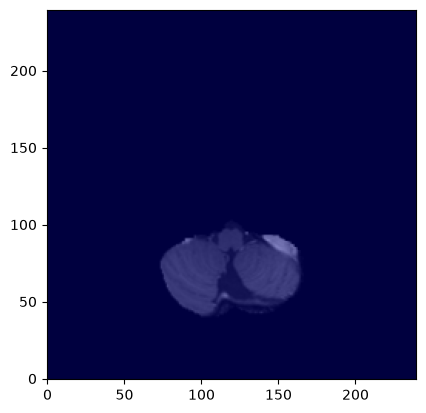

In [31]:
nii_img = nib.load(DATA_ROOT / 'imagesTr' / 'BRATS_001.nii.gz')

data = nii_img.get_fdata()
print(data.shape)
slice_to_show = data[:,:,20,2]
label_nii= nib.load(DATA_ROOT / 'labelsTr' / 'BRATS_001.nii.gz')

label_data = label_nii.get_fdata()

plt.imshow(slice_to_show.T, cmap='gray', origin='lower')
print(label_data.shape)
label_slice_to_show = label_data[:,:,20]
plt.imshow(label_slice_to_show.T, cmap='jet',alpha=0.5, origin='lower')
plt.show()


(240, 240, 155, 4)
(240, 240, 155)


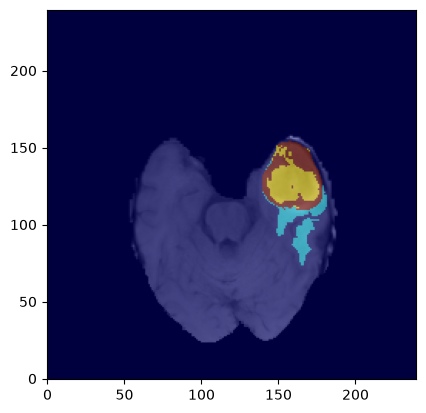

In [32]:
nii_img = nib.load(DATA_ROOT / 'imagesTr' / 'BRATS_001.nii.gz') 

data = nii_img.get_fdata()
print(data.shape)
slice_to_show = data[:,:,50,1]
label_nii= nib.load(DATA_ROOT / 'labelsTr' / 'BRATS_001.nii.gz')

label_data = label_nii.get_fdata()

plt.imshow(slice_to_show.T, cmap='gray', origin='lower')
print(label_data.shape)
label_slice_to_show = label_data[:,:,50]
plt.imshow(label_slice_to_show.T, cmap='jet',alpha=0.5, origin='lower')
plt.show()


In [33]:
image_files = sorted(image_dir.glob('*.nii.gz'))[:3]

for image_path in image_files:
    case_id = image_path.name.replace('.nii.gz', '')
    label_path = label_dir / f'{case_id}.nii.gz'
    image_data = nib.load(image_path).get_fdata()
    label_data = nib.load(label_path).get_fdata()
    print(f'Case: {case_id}, Image shape: {image_data.shape}, Label shape: {label_data.shape}, Unique labels: {np.unique(label_data)}')
    

Case: BRATS_001, Image shape: (240, 240, 155, 4), Label shape: (240, 240, 155), Unique labels: [0. 1. 2. 3.]
Case: BRATS_002, Image shape: (240, 240, 155, 4), Label shape: (240, 240, 155), Unique labels: [0. 1. 2. 3.]
Case: BRATS_003, Image shape: (240, 240, 155, 4), Label shape: (240, 240, 155), Unique labels: [0. 1. 2. 3.]


In [34]:
import json
import pandas as pd

with open(DATA_ROOT / "dataset.json") as f:
    dataset_info = json.load(f)
modality_map = dataset_info["modality"]

split_df = pd.read_csv("assignment2_split(in).csv")
train_df = split_df[split_df["split"] == "train"].head(3)

for _, row in train_df.iterrows():
    case_id = row["case_id"]
    image_path = DATA_ROOT / row["image_relpath"]
    label_path = DATA_ROOT / row["label_relpath"]

    image_nii = nib.load(image_path)
    label_nii = nib.load(label_path)

    image_data = image_nii.get_fdata()
    label_data = label_nii.get_fdata()

    print(f"\nCase: {case_id}")

    print("Image shape:", image_data.shape)
    print("Label shape:", label_data.shape)

    print("Number of channels:", image_data.shape[-1])
    print("Channel order:", {int(k): v for k, v in modality_map.items()})

    print("Affine matrix:")
    print(image_nii.affine)

    print("Orientation codes:", nib.aff2axcodes(image_nii.affine))


    print("Voxel spacing in mm:", image_nii.header.get_zooms()[:3])

    print("Image/label geometry match:",
          np.allclose(image_nii.affine, label_nii.affine)
          and image_data.shape[:3] == label_data.shape)

    print("Unique label values:", np.unique(label_data))


Case: BRATS_001
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Number of channels: 4
Channel order: {0: 'FLAIR', 1: 'T1w', 2: 't1gd', 3: 'T2w'}
Affine matrix:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Voxel spacing in mm: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Image/label geometry match: True
Unique label values: [0. 1. 2. 3.]

Case: BRATS_003
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Number of channels: 4
Channel order: {0: 'FLAIR', 1: 'T1w', 2: 't1gd', 3: 'T2w'}
Affine matrix:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Voxel spacing in mm: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Image/label geometry match: True
Unique label values: [0. 1. 2. 3.]

Case: BRATS_004
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Number of channels: 4
Channel order: {0: 'FLAIR', 1: 'T1w', 2: 't1gd', 3: 'T2w'}
Affine matrix:
[[1.

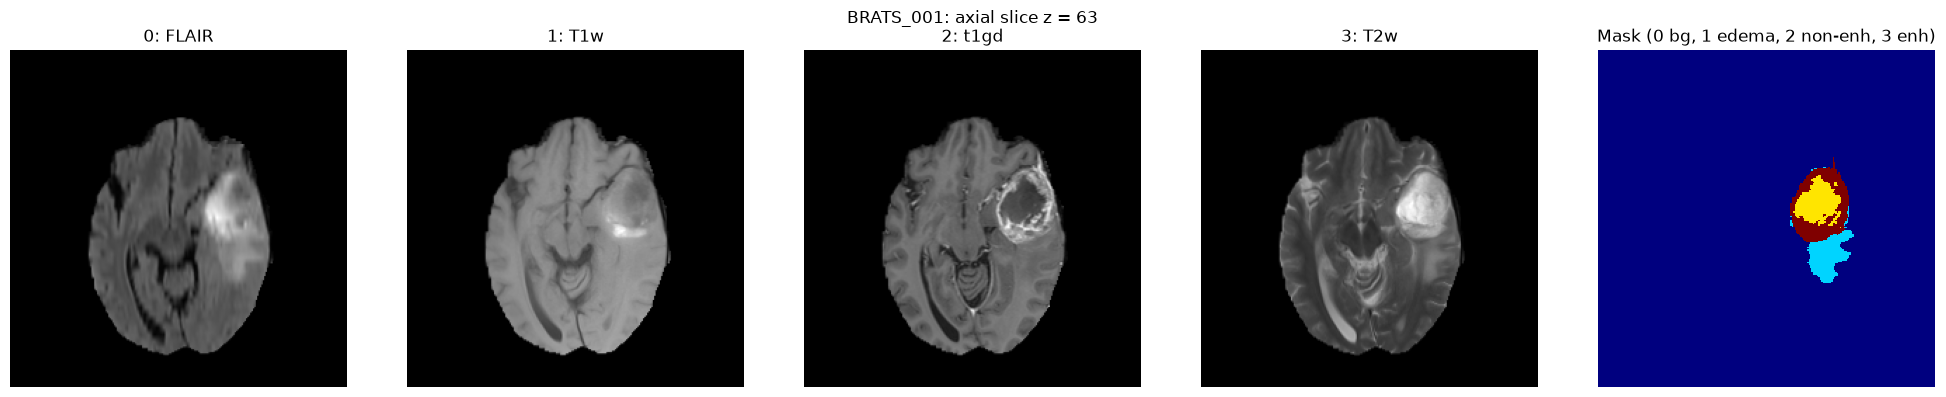

In [35]:
case_id = "BRATS_001"
image_nii = nib.load(image_dir / f"{case_id}.nii.gz")
label_nii = nib.load(label_dir / f"{case_id}.nii.gz")
image_data = image_nii.get_fdata()
label_data = label_nii.get_fdata()

z = int(np.argmax((label_data > 0).sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for c in range(image_data.shape[-1]):
    axes[c].imshow(image_data[:, :, z, c].T, cmap="gray", origin="lower")
    axes[c].set_title(f"{c}: {modality_map[str(c)]}")
    axes[c].axis("off")

axes[4].imshow(label_data[:, :, z].T, cmap="jet", origin="lower",
               vmin=0, vmax=3, interpolation="nearest")
axes[4].set_title("Mask (0 bg, 1 edema, 2 non-enh, 3 enh)")
axes[4].axis("off")

fig.suptitle(f"{case_id}: axial slice z = {z}")
plt.tight_layout()
plt.show()

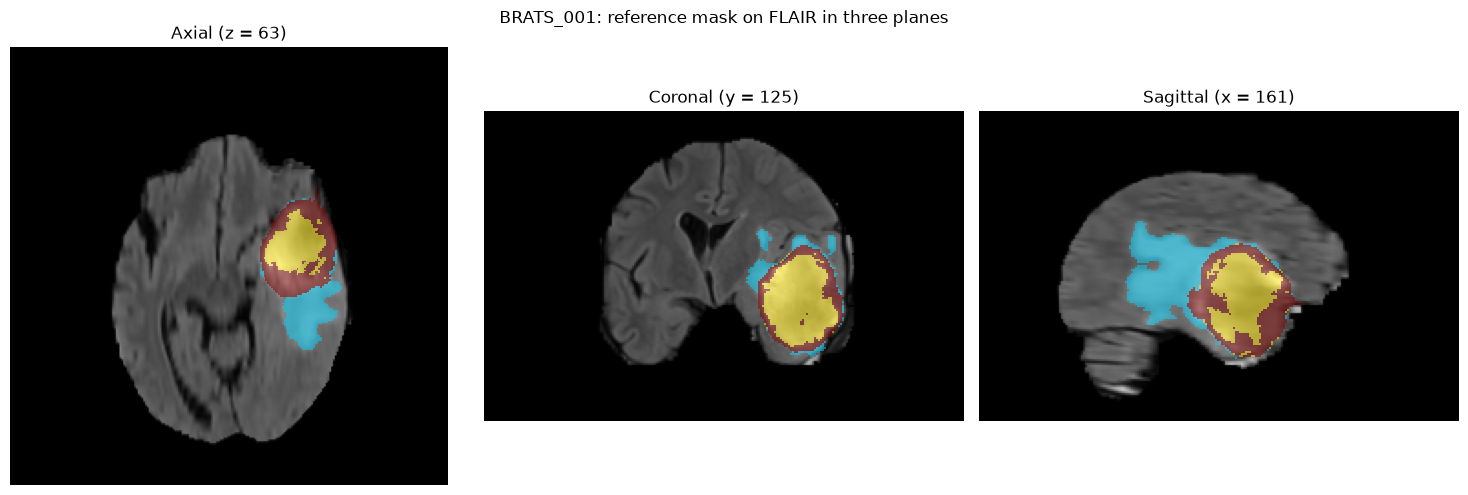

In [36]:
tumour = label_data > 0

x = int(np.argmax(tumour.sum(axis=(1, 2))))   # sagittal index (axis 0: L -> R)
y = int(np.argmax(tumour.sum(axis=(0, 2))))   # coronal index  (axis 1: P -> A)
z = int(np.argmax(tumour.sum(axis=(0, 1))))   # axial index    (axis 2: I -> S)

flair = image_data[..., 0]                    
mask = np.ma.masked_where(label_data == 0, label_data)   

views = [
    (f"Axial (z = {z})",    flair[:, :, z], mask[:, :, z]),
    (f"Coronal (y = {y})",  flair[:, y, :], mask[:, y, :]),
    (f"Sagittal (x = {x})", flair[x, :, :], mask[x, :, :]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, img, msk) in zip(axes, views):
    ax.imshow(img.T, cmap="gray", origin="lower")
    ax.imshow(msk.T, cmap="jet", alpha=0.5, origin="lower",
              vmin=0, vmax=3, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"{case_id}: reference mask on {modality_map['0']} in three planes")
plt.tight_layout()
plt.show()

In [37]:
import pandas as pd

split_df = pd.read_csv("assignment2_split(in).csv")   # or "assignment2_split.csv" after renaming

print(split_df.head())
print()
print(split_df["split"].value_counts())

     case_id  split              image_relpath              label_relpath
0  BRATS_001  train  imagesTr/BRATS_001.nii.gz  labelsTr/BRATS_001.nii.gz
1  BRATS_002   test  imagesTr/BRATS_002.nii.gz  labelsTr/BRATS_002.nii.gz
2  BRATS_003  train  imagesTr/BRATS_003.nii.gz  labelsTr/BRATS_003.nii.gz
3  BRATS_004  train  imagesTr/BRATS_004.nii.gz  labelsTr/BRATS_004.nii.gz
4  BRATS_005  train  imagesTr/BRATS_005.nii.gz  labelsTr/BRATS_005.nii.gz

split
train         338
test           73
validation     73
Name: count, dtype: int64


In [38]:
missing_images = [p for p in split_df["image_relpath"] if not (DATA_ROOT / p).exists()]
missing_labels = [p for p in split_df["label_relpath"] if not (DATA_ROOT / p).exists()]

print("Rows in CSV:", len(split_df))
print("Missing image files:", len(missing_images))
print("Missing label files:", len(missing_labels))

if missing_images or missing_labels:
    print("Missing images:", missing_images)
    print("Missing labels:", missing_labels)

assert len(split_df) == 484, "Expected 484 rows in the split CSV"
assert not missing_images and not missing_labels, "Some files listed in the CSV are missing"

Rows in CSV: 484
Missing image files: 0
Missing label files: 0


In [39]:
n_duplicates = split_df["case_id"].duplicated().sum()
print("Duplicate case_id rows:", n_duplicates)

train_ids = set(split_df.loc[split_df["split"] == "train", "case_id"])
val_ids   = set(split_df.loc[split_df["split"] == "validation", "case_id"])
test_ids  = set(split_df.loc[split_df["split"] == "test", "case_id"])

print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:      ", len(train_ids & test_ids))
print("Validation ∩ Test: ", len(val_ids & test_ids))

print("Total unique cases:", len(train_ids | val_ids | test_ids))

assert n_duplicates == 0, "Some case_id values appear more than once"
assert not (train_ids & val_ids or train_ids & test_ids or val_ids & test_ids), "Splits overlap"
assert len(train_ids | val_ids | test_ids) == len(split_df) == 484

Duplicate case_id rows: 0
Train ∩ Validation: 0
Train ∩ Test:       0
Validation ∩ Test:  0
Total unique cases: 484


In [40]:
volume_rows = []

trainval_df = split_df[split_df["split"].isin(["train", "validation"])]

for _, row in trainval_df.iterrows():
    label_nii = nib.load(DATA_ROOT / row["label_relpath"])
    label_data = np.asarray(label_nii.dataobj)

    n_tumour_voxels = int((label_data > 0).sum())
    voxel_volume_mm3 = float(np.prod(label_nii.header.get_zooms()[:3]))
    volume_ml = n_tumour_voxels * voxel_volume_mm3 / 1000.0

    volume_rows.append({"case_id": row["case_id"],
                        "split": row["split"],
                        "volume_ml": volume_ml})

volume_df = pd.DataFrame(volume_rows)

print("Cases measured:", len(volume_df))
print(volume_df.groupby("split")["volume_ml"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2))

Cases measured: 411
            count    mean  median   min     max
split                                          
train         338  102.96   95.48  8.48  265.25
validation     73  100.76   91.56  7.28  266.94


In [41]:
ref_nii = nib.load(DATA_ROOT / "imagesTr" / "BRATS_001.nii.gz")

ref_shape = ref_nii.shape[:3]
ref_affine = ref_nii.affine
ref_spacing = ref_nii.header.get_zooms()[:3]

print("Reference shape:", ref_shape)
print("Reference affine:\n", ref_affine)
print("Reference spacing:", ref_spacing)

Reference shape: (240, 240, 155)
Reference affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Reference spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0))


In [42]:
check_a_mismatches = []
check_b_mismatches = []

n_loaded = 0

for _, row in split_df.iterrows():
    image_nii = nib.load(DATA_ROOT / row["image_relpath"])
    label_nii = nib.load(DATA_ROOT / row["label_relpath"])
    n_loaded += 1

print("Cases loaded:", n_loaded)

Cases loaded: 484


In [43]:
check_a_mismatches = []
check_b_mismatches = []

n_loaded = 0

for _, row in split_df.iterrows():
    image_nii = nib.load(DATA_ROOT / row["image_relpath"])
    label_nii = nib.load(DATA_ROOT / row["label_relpath"])
    n_loaded += 1

    image_shape = image_nii.shape[:3]
    image_affine = image_nii.affine
    image_spacing = image_nii.header.get_zooms()[:3]

    same_shape = image_shape == label_nii.shape[:3]
    same_affine = np.allclose(image_affine, label_nii.affine)
    same_spacing = np.allclose(image_spacing, label_nii.header.get_zooms()[:3])

    if not (same_shape and same_affine and same_spacing):
        check_a_mismatches.append(row["case_id"])

    ref_same_shape = image_shape == ref_shape
    ref_same_affine = np.allclose(image_affine, ref_affine)
    ref_same_spacing = np.allclose(image_spacing, ref_spacing)

    if not (ref_same_shape and ref_same_affine and ref_same_spacing):
        check_b_mismatches.append(row["case_id"])

print("Cases loaded:", n_loaded)
print("Check A mismatches (image vs label):", len(check_a_mismatches))
print("Check B mismatches (case vs reference):", len(check_b_mismatches))

if check_a_mismatches:
    print("Check A mismatching IDs:", check_a_mismatches)
if check_b_mismatches:
    print("Check B mismatching IDs:", check_b_mismatches)

assert n_loaded == 484, f"Expected 484 cases, loaded {n_loaded}"
assert len(check_a_mismatches) == 0, f"{len(check_a_mismatches)} cases have image/label geometry mismatches"
assert len(check_b_mismatches) == 0, f"{len(check_b_mismatches)} cases differ from the reference geometry"

Cases loaded: 484
Check A mismatches (image vs label): 0
Check B mismatches (case vs reference): 0


In [44]:
from scipy.ndimage import zoom

demo_case = split_df.loc[split_df["split"] == "train", "case_id"].iloc[0]
demo_image_nii = nib.load(DATA_ROOT / "imagesTr" / f"{demo_case}.nii.gz")
demo_label_nii = nib.load(DATA_ROOT / "labelsTr" / f"{demo_case}.nii.gz")

demo_label = np.asarray(demo_label_nii.dataobj).astype(np.float32)
demo_flair = np.asarray(demo_image_nii.dataobj)[..., 0].astype(np.float32)

factor = 0.5

label_nearest = zoom(demo_label, factor, order=0)
label_linear = zoom(demo_label, factor, order=1)
flair_linear = zoom(demo_flair, factor, order=1)

print("Case:", demo_case)
print("Original shape:", demo_label.shape, "-> resampled shape:", label_nearest.shape)
print()
print("Original label values:", np.unique(demo_label))
print("Label, order=0 values:", np.unique(label_nearest))
label_linear_values = np.unique(label_linear)
print("Label, order=1: number of unique values:", len(label_linear_values))
print("Label, order=1 sample values:", np.round(label_linear_values[:10], 3))
print()
print("FLAIR original range:", demo_flair.min(), "to", demo_flair.max())
print("FLAIR order=1 range:", flair_linear.min(), "to", flair_linear.max())

Case: BRATS_001
Original shape: (240, 240, 155) -> resampled shape: (120, 120, 78)

Original label values: [0. 1. 2. 3.]
Label, order=0 values: [0. 1. 2. 3.]
Label, order=1: number of unique values: 1970
Label, order=1 sample values: [0.    0.089 0.09  0.09  0.091 0.094 0.094 0.094 0.095 0.096]

FLAIR original range: 0.0 to 1829.0
FLAIR order=1 range: 0.0 to 1726.191


In [45]:
def normalize_brain(image):
    normalized = np.zeros_like(image, dtype=np.float32)
    for c in range(image.shape[-1]):
        channel = image[..., c]
        brain = channel != 0
        mean = channel[brain].mean()
        std = channel[brain].std()
        if std == 0:
            std = 1.0
        normalized[..., c][brain] = (channel[brain] - mean) / std
    return normalized


demo_cases = split_df.loc[split_df["split"] == "train", "case_id"].iloc[:2]

for case_id in demo_cases:
    image = np.asarray(nib.load(DATA_ROOT / "imagesTr" / f"{case_id}.nii.gz").dataobj).astype(np.float32)
    image_norm = normalize_brain(image)

    print(f"\nCase: {case_id}")
    print(f"{'Channel':<8}{'brain %':>9}{'all-vox mean':>14}{'all-vox SD':>12}"
          f"{'brain mean':>12}{'brain SD':>10}{'norm mean':>11}{'norm SD':>9}")

    for c in range(image.shape[-1]):
        channel = image[..., c]
        brain = channel != 0
        norm_brain = image_norm[..., c][brain]
        print(f"{modality_map[str(c)]:<8}"
              f"{100 * brain.mean():>8.1f}%"
              f"{channel.mean():>14.2f}{channel.std():>12.2f}"
              f"{channel[brain].mean():>12.2f}{channel[brain].std():>10.2f}"
              f"{norm_brain.mean():>11.3f}{norm_brain.std():>9.3f}")

    print("Background still 0:", np.all(image_norm[image[..., 0] == 0, 0] == 0))


Case: BRATS_001
Channel   brain %  all-vox mean  all-vox SD  brain mean  brain SD  norm mean  norm SD
FLAIR       16.7%         86.02      210.89      516.27    211.65      0.000    1.000
T1w         16.7%        130.18      302.97      780.64    206.55     -0.000    1.000
t1gd        16.7%        121.47      288.59      728.44    239.42     -0.000    1.000
T2w         16.7%         78.69      195.86      471.84    211.00     -0.000    1.000
Background still 0: True

Case: BRATS_003
Channel   brain %  all-vox mean  all-vox SD  brain mean  brain SD  norm mean  norm SD
FLAIR       18.9%         97.25      222.07      513.62    215.86     -0.000    1.000
T1w         19.7%        150.24      318.08      761.64    217.33      0.000    1.000
t1gd        19.7%         89.53      206.29      454.26    224.15     -0.000    1.000
T2w         19.7%         97.38      217.35      493.67    209.40      0.000    1.000
Background still 0: True


In [46]:
def nonzero_bounds(mask):
    if not mask.any():
        return None
    bounds = []
    for axis in range(3):
        other_axes = tuple(a for a in range(3) if a != axis)
        idx = np.where(mask.any(axis=other_axes))[0]
        bounds.append((int(idx[0]), int(idx[-1])))
    return bounds


trainval_df = split_df[split_df["split"].isin(["train", "validation"])]

extent_rows = []

for _, row in trainval_df.iterrows():
    image = np.asarray(nib.load(DATA_ROOT / row["image_relpath"]).dataobj)
    label = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj)

    brain_bounds = nonzero_bounds(np.any(image != 0, axis=-1))
    tumour_bounds = nonzero_bounds(label > 0)

    extent_rows.append({"case_id": row["case_id"],
                        "brain_bounds": brain_bounds,
                        "tumour_bounds": tumour_bounds})

original_shape = image.shape[:3]
print("Cases scanned:", len(extent_rows))

Cases scanned: 411


In [47]:
PATCH_SIZE = np.array([96, 96, 96])
MULTIPLE = 16
MARGIN = 4

dims = np.array(original_shape)
brain_mins = np.array([[b[0] for b in r["brain_bounds"]] for r in extent_rows])
brain_maxs = np.array([[b[1] for b in r["brain_bounds"]] for r in extent_rows])

global_min = brain_mins.min(axis=0)
global_max = brain_maxs.max(axis=0)

needed = (global_max - global_min + 1) + 2 * MARGIN
crop_size = np.maximum(np.ceil(needed / MULTIPLE) * MULTIPLE, PATCH_SIZE).astype(int)

center = (global_min + global_max + 1) / 2
crop_start = np.round(center - crop_size / 2).astype(int)
for a in range(3):
    if crop_size[a] <= dims[a]:
        crop_start[a] = np.clip(crop_start[a], 0, dims[a] - crop_size[a])
crop_end = crop_start + crop_size


def _slices(start, size, shape):
    src_lo = np.maximum(start, 0)
    src_hi = np.minimum(start + size, shape)
    dst_lo = src_lo - start
    dst_hi = dst_lo + (src_hi - src_lo)
    src = tuple(slice(lo, hi) for lo, hi in zip(src_lo, src_hi))
    dst = tuple(slice(lo, hi) for lo, hi in zip(dst_lo, dst_hi))
    return src, dst


def crop_or_pad(volume, start=crop_start, size=crop_size):
    out = np.zeros(tuple(size) + volume.shape[3:], dtype=volume.dtype)
    src, dst = _slices(start, size, np.array(volume.shape[:3]))
    out[dst] = volume[src]
    return out


def uncrop(cropped, start=crop_start, shape=original_shape):
    out = np.zeros(tuple(shape) + cropped.shape[3:], dtype=cropped.dtype)
    src, dst = _slices(start, np.array(cropped.shape[:3]), np.array(shape))
    out[src] = cropped[dst]
    return out


def inside_box(bounds):
    return all(crop_start[a] <= lo and hi < crop_end[a] for a, (lo, hi) in enumerate(bounds))


brain_cut = [r["case_id"] for r in extent_rows if not inside_box(r["brain_bounds"])]
tumour_cut = [r["case_id"] for r in extent_rows
              if r["tumour_bounds"] is not None and not inside_box(r["tumour_bounds"])]

test_label = np.asarray(nib.load(DATA_ROOT / trainval_df.iloc[0]["label_relpath"]).dataobj)
round_trip_ok = np.array_equal(uncrop(crop_or_pad(test_label)), test_label)

print("Brain extent over all cases (min, max per axis):", global_min, global_max)
print("Original shape:", tuple(dims))
print("Crop start:", tuple(crop_start), "crop end:", tuple(crop_end))
print("Cropped shape:", tuple(crop_size))
print("Padding needed on any axis:", bool(np.any(crop_start < 0) or np.any(crop_end > dims)))
print(f"Volume removed: {100 * (1 - np.prod(crop_size) / np.prod(dims)):.1f}%")
print("Cases with brain cut by the box:", len(brain_cut))
print("Cases with tumour cut by the box:", len(tumour_cut))
print("Crop -> uncrop round trip exact:", round_trip_ok)

assert len(brain_cut) == 0 and len(tumour_cut) == 0
assert round_trip_ok

Brain extent over all cases (min, max per axis): [38 19  0] [199 210 148]
Original shape: (np.int64(240), np.int64(240), np.int64(155))
Crop start: (np.int64(31), np.int64(11), np.int64(-6)) crop end: (np.int64(207), np.int64(219), np.int64(154))
Cropped shape: (np.int64(176), np.int64(208), np.int64(160))
Padding needed on any axis: True
Volume removed: 34.4%
Cases with brain cut by the box: 0
Cases with tumour cut by the box: 0
Crop -> uncrop round trip exact: True


In [48]:
def _slices(start, size, shape):
    src_lo = np.maximum(start, 0)
    src_hi = np.minimum(start + size, shape)
    dst_lo = src_lo - start
    dst_hi = dst_lo + (src_hi - src_lo)
    src = tuple(slice(lo, hi) for lo, hi in zip(src_lo, src_hi))
    dst = tuple(slice(lo, hi) for lo, hi in zip(dst_lo, dst_hi))
    return src, dst


def crop_or_pad(volume, crop_start, crop_size):
    out = np.zeros(tuple(crop_size) + volume.shape[3:], dtype=volume.dtype)
    src, dst = _slices(crop_start, crop_size, np.array(volume.shape[:3]))
    out[dst] = volume[src]
    return out


def uncrop(cropped, crop_start, original_shape):
    out = np.zeros(tuple(original_shape) + cropped.shape[3:], dtype=cropped.dtype)
    src, dst = _slices(crop_start, np.array(cropped.shape[:3]), np.array(original_shape))
    out[src] = cropped[dst]
    return out


def inside_box(bounds, crop_start, crop_size):
    crop_end = crop_start + crop_size
    return all(crop_start[a] <= lo and hi < crop_end[a] for a, (lo, hi) in enumerate(bounds))


brain_cut = [r["case_id"] for r in extent_rows
             if not inside_box(r["brain_bounds"], crop_start, crop_size)]
tumour_cut = [r["case_id"] for r in extent_rows
              if r["tumour_bounds"] is not None
              and not inside_box(r["tumour_bounds"], crop_start, crop_size)]

test_label = np.asarray(nib.load(DATA_ROOT / trainval_df.iloc[0]["label_relpath"]).dataobj)
round_trip_ok = np.array_equal(
    uncrop(crop_or_pad(test_label, crop_start, crop_size), crop_start, original_shape),
    test_label)

print("Brain extent over all cases (min, max per axis):", global_min, global_max)
print("Original shape:", tuple(dims))
print("Crop start:", tuple(crop_start), "crop end:", tuple(crop_end))
print("Cropped shape:", tuple(crop_size))
print("Padding needed on any axis:", bool(np.any(crop_start < 0) or np.any(crop_end > dims)))
print(f"Volume removed: {100 * (1 - np.prod(crop_size) / np.prod(dims)):.1f}%")
print("Cases with brain cut by the box:", len(brain_cut))
print("Cases with tumour cut by the box:", len(tumour_cut))
print("Crop -> uncrop round trip exact:", round_trip_ok)

assert len(brain_cut) == 0 and len(tumour_cut) == 0
assert round_trip_ok

Brain extent over all cases (min, max per axis): [38 19  0] [199 210 148]
Original shape: (np.int64(240), np.int64(240), np.int64(155))
Crop start: (np.int64(31), np.int64(11), np.int64(-6)) crop end: (np.int64(207), np.int64(219), np.int64(154))
Cropped shape: (np.int64(176), np.int64(208), np.int64(160))
Padding needed on any axis: True
Volume removed: 34.4%
Cases with brain cut by the box: 0
Cases with tumour cut by the box: 0
Crop -> uncrop round trip exact: True


In [49]:
test_df = split_df[split_df["split"] == "test"]

test_brain_cut = []

for _, row in test_df.iterrows():
    image = np.asarray(nib.load(DATA_ROOT / row["image_relpath"]).dataobj)
    bounds = nonzero_bounds(np.any(image != 0, axis=-1))
    if not inside_box(bounds, crop_start, crop_size):
        test_brain_cut.append(row["case_id"])

print("Test images checked:", len(test_df))
print("Test images with brain outside the box:", len(test_brain_cut))
if test_brain_cut:
    print("IDs:", test_brain_cut)

assert len(test_brain_cut) == 0

Test images checked: 73
Test images with brain outside the box: 0


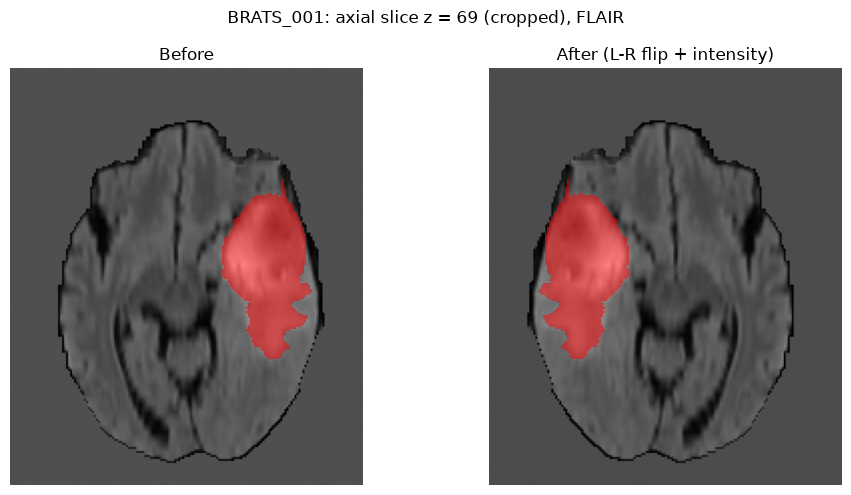

Flipped: True
Scales per channel: [0.988 1.072 1.039 0.919]
Shifts per channel: [ 0.095  0.052  0.057 -0.074]
Label values before: [0 1]
Label values after:  [0 1]
Tumour voxels before / after: 111724 111724
Background still 0: True


In [50]:
def augment(image, label, rng, p_flip=0.5, scale_range=0.1, shift_range=0.1):
    image = image.copy()
    label = label.copy()

    flipped = rng.random() < p_flip
    if flipped:
        image = np.flip(image, axis=0).copy()
        label = np.flip(label, axis=0).copy()

    scales = rng.uniform(1 - scale_range, 1 + scale_range, size=image.shape[-1])
    shifts = rng.uniform(-shift_range, shift_range, size=image.shape[-1])
    for c in range(image.shape[-1]):
        brain = image[..., c] != 0
        image[..., c][brain] = image[..., c][brain] * scales[c] + shifts[c]

    return image, label, {"flipped": flipped, "scales": scales, "shifts": shifts}


rng = np.random.default_rng(42)

demo_case = split_df.loc[split_df["split"] == "train", "case_id"].iloc[0]
demo_image = np.asarray(nib.load(DATA_ROOT / "imagesTr" / f"{demo_case}.nii.gz").dataobj).astype(np.float32)
demo_label = np.asarray(nib.load(DATA_ROOT / "labelsTr" / f"{demo_case}.nii.gz").dataobj)

demo_image = crop_or_pad(normalize_brain(demo_image), crop_start, crop_size)
demo_label = crop_or_pad((demo_label > 0).astype(np.uint8), crop_start, crop_size)

aug_image, aug_label, params = augment(demo_image, demo_label, rng, p_flip=1.0)

z = int(np.argmax(demo_label.sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, lbl, title in [
    (axes[0], demo_image, demo_label, "Before"),
    (axes[1], aug_image, aug_label, "After (L-R flip + intensity)"),
]:
    ax.imshow(img[:, :, z, 0].T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_where(lbl[:, :, z] == 0, lbl[:, :, z]).T,
              cmap="autumn", alpha=0.5, origin="lower", interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
fig.suptitle(f"{demo_case}: axial slice z = {z} (cropped), {modality_map['0']}")
plt.tight_layout()
plt.show()

print("Flipped:", params["flipped"])
print("Scales per channel:", np.round(params["scales"], 3))
print("Shifts per channel:", np.round(params["shifts"], 3))
print("Label values before:", np.unique(demo_label))
print("Label values after: ", np.unique(aug_label))
print("Tumour voxels before / after:", int(demo_label.sum()), int(aug_label.sum()))
print("Background still 0:", np.all(aug_image[demo_image == 0] == 0) if not params["flipped"]
      else np.all(aug_image[np.flip(demo_image, axis=0) == 0] == 0))

In [51]:
def preprocess_case(image_path, label_path=None, crop_start=crop_start, crop_size=crop_size):
    image = np.asarray(nib.load(image_path).dataobj).astype(np.float32)
    image = normalize_brain(image)
    image = crop_or_pad(image, crop_start, crop_size)
    image = np.moveaxis(image, -1, 0).astype(np.float32)

    if label_path is None:
        return image, None

    label = np.asarray(nib.load(label_path).dataobj)
    label = crop_or_pad((label > 0).astype(np.uint8), crop_start, crop_size)
    label = label[np.newaxis].astype(np.uint8)

    return image, label


row = split_df[split_df["split"] == "train"].iloc[0]
image_path = DATA_ROOT / row["image_relpath"]
label_path = DATA_ROOT / row["label_relpath"]

image, label = preprocess_case(image_path, label_path, crop_start, crop_size)

raw_label = np.asarray(nib.load(label_path).dataobj)

print("Case:", row["case_id"])
print("Image shape:", image.shape, "dtype:", image.dtype)
print("Label shape:", label.shape, "dtype:", label.dtype)
print()
for c in range(image.shape[0]):
    brain = image[c] != 0
    print(f"{modality_map[str(c)]:<6} brain mean: {image[c][brain].mean():.3f}  SD: {image[c][brain].std():.3f}")
print()
print("Label unique values:", np.unique(label))
print("Tumour voxels uncropped:", int((raw_label > 0).sum()))
print("Tumour voxels after preprocessing:", int(label.sum()))

Case: BRATS_001
Image shape: (4, 176, 208, 160) dtype: float32
Label shape: (1, 176, 208, 160) dtype: uint8

FLAIR  brain mean: 0.000  SD: 1.000
T1w    brain mean: -0.000  SD: 1.000
t1gd   brain mean: -0.000  SD: 1.000
T2w    brain mean: -0.000  SD: 1.000

Label unique values: [0 1]
Tumour voxels uncropped: 111724
Tumour voxels after preprocessing: 111724


In [52]:
def augment(image, label, rng, p_flip=0.5, scale_range=0.1, shift_range=0.1):
    image = image.copy()
    label = label.copy()

    flipped = rng.random() < p_flip
    if flipped:
        image = np.flip(image, axis=1).copy()
        label = np.flip(label, axis=1).copy()

    scales = rng.uniform(1 - scale_range, 1 + scale_range, size=image.shape[0])
    shifts = rng.uniform(-shift_range, shift_range, size=image.shape[0])
    for c in range(image.shape[0]):
        brain = image[c] != 0
        image[c][brain] = image[c][brain] * scales[c] + shifts[c]

    return image, label, {"flipped": flipped, "scales": scales, "shifts": shifts}

In [53]:
import time
import json

def build_cache(df, cache_dir, crop_start, crop_size, limit=None, overwrite=False):
    cache_dir.mkdir(parents=True, exist_ok=True)

    with open(cache_dir / "crop_box.json", "w") as f:
        json.dump({"crop_start": crop_start.tolist(),
                   "crop_size": crop_size.tolist(),
                   "original_shape": list(original_shape)}, f)

    rows = df if limit is None else df.head(limit)
    times = []

    for i, (_, row) in enumerate(rows.iterrows(), start=1):
        img_file = cache_dir / f"{row['case_id']}_img.npy"
        lbl_file = cache_dir / f"{row['case_id']}_lbl.npy"

        if img_file.exists() and lbl_file.exists() and not overwrite:
            continue

        t0 = time.time()
        image, label = preprocess_case(DATA_ROOT / row["image_relpath"],
                                       DATA_ROOT / row["label_relpath"],
                                       crop_start, crop_size)
        np.save(img_file, image.astype(np.float16))
        np.save(lbl_file, label.astype(np.uint8))
        times.append(time.time() - t0)

        if limit is not None:
            print(f"{row['case_id']}: img {img_file.stat().st_size / 1e6:.1f} MB, "
                  f"lbl {lbl_file.stat().st_size / 1e6:.1f} MB, {times[-1]:.1f} s")
        elif i % 25 == 0:
            print(f"{i}/{len(rows)} done, avg {np.mean(times):.1f} s/case")

    if times:
        print(f"Processed {len(times)} cases, avg {np.mean(times):.1f} s/case, "
              f"total {sum(times) / 60:.1f} min")
    else:
        print("Nothing to do, all files already cached")


trainval_df = split_df[split_df["split"].isin(["train", "validation"])]

build_cache(trainval_df, CACHE_DIR, crop_start, crop_size, limit=3)

Nothing to do, all files already cached


In [54]:
case_id = trainval_df.iloc[0]["case_id"]
cached_img = np.load(CACHE_DIR / f"{case_id}_img.npy")
cached_lbl = np.load(CACHE_DIR / f"{case_id}_lbl.npy")

fresh_img, fresh_lbl = preprocess_case(DATA_ROOT / trainval_df.iloc[0]["image_relpath"],
                                       DATA_ROOT / trainval_df.iloc[0]["label_relpath"],
                                       crop_start, crop_size)

print("Image shape / dtype:", cached_img.shape, cached_img.dtype)
print("Label shape / dtype:", cached_lbl.shape, cached_lbl.dtype)
print("Max float16 rounding error:", float(np.abs(cached_img.astype(np.float32) - fresh_img).max()))
print("Label identical:", np.array_equal(cached_lbl, fresh_lbl))
print("Tumour voxels:", int(cached_lbl.sum()))

Image shape / dtype: (4, 176, 208, 160) float16
Label shape / dtype: (1, 176, 208, 160) uint8
Max float16 rounding error: 0.0019512176513671875
Label identical: True
Tumour voxels: 111724


In [57]:
build_cache(trainval_df, CACHE_DIR, crop_start, crop_size, limit=None)

25/411 done, avg 2.3 s/case
50/411 done, avg 2.3 s/case
75/411 done, avg 2.3 s/case
100/411 done, avg 2.3 s/case
125/411 done, avg 2.3 s/case
150/411 done, avg 2.3 s/case
175/411 done, avg 2.3 s/case
200/411 done, avg 2.3 s/case
225/411 done, avg 2.3 s/case
250/411 done, avg 2.3 s/case
275/411 done, avg 2.2 s/case
300/411 done, avg 2.2 s/case
325/411 done, avg 2.2 s/case
350/411 done, avg 2.2 s/case
375/411 done, avg 2.2 s/case
400/411 done, avg 2.2 s/case
Processed 408 cases, avg 2.2 s/case, total 15.1 min


In [58]:
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
PATCH_SIZE = (96, 96, 96)


class PatchDataset(Dataset):
    def __init__(self, case_ids, cache_dir, patch_size=PATCH_SIZE, patches_per_epoch=200,
                 augment=False, sampler="uniform", seed=SEED):
        self.case_ids = list(case_ids)
        self.cache_dir = Path(cache_dir)
        self.patch_size = np.array(patch_size)
        self.patches_per_epoch = patches_per_epoch
        self.augment = augment
        self.sampler = sampler
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self.patches_per_epoch

    def _pick_corner(self, label, volume_shape):
        max_corner = volume_shape - self.patch_size
        if self.sampler == "uniform":
            return np.array([self.rng.integers(0, m + 1) for m in max_corner])
        raise NotImplementedError(f"sampler '{self.sampler}' not implemented yet")

    def __getitem__(self, idx):
        case_id = self.case_ids[self.rng.integers(len(self.case_ids))]
        image = np.load(self.cache_dir / f"{case_id}_img.npy", mmap_mode="r")
        label = np.load(self.cache_dir / f"{case_id}_lbl.npy", mmap_mode="r")

        corner = self._pick_corner(label, np.array(image.shape[1:]))
        a, b, c = corner
        pa, pb, pc = self.patch_size

        img_patch = np.array(image[:, a:a + pa, b:b + pb, c:c + pc], dtype=np.float32)
        lbl_patch = np.array(label[:, a:a + pa, b:b + pb, c:c + pc], dtype=np.float32)

        if self.augment:
            img_patch, lbl_patch, _ = augment(img_patch, lbl_patch, self.rng)

        return torch.from_numpy(img_patch), torch.from_numpy(lbl_patch)


def worker_init_fn(worker_id):
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.default_rng(torch.initial_seed() % 2**32)


train_ids = split_df.loc[split_df["split"] == "train", "case_id"].tolist()
missing = [c for c in train_ids if not (CACHE_DIR / f"{c}_img.npy").exists()]
print("Train cases:", len(train_ids), "| missing from cache:", len(missing))

train_ds = PatchDataset(train_ids, CACHE_DIR, PATCH_SIZE, patches_per_epoch=200,
                        augment=True, sampler="uniform")

train_loader = DataLoader(train_ds, batch_size=2, shuffle=False, num_workers=4,
                          worker_init_fn=worker_init_fn,
                          generator=torch.Generator().manual_seed(SEED),
                          persistent_workers=False)

images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape), images.dtype)
print("Label batch:", tuple(labels.shape), labels.dtype)
print("Label unique values:", torch.unique(labels).tolist())
print("Patches with tumour in this batch:", (labels.flatten(1).sum(1) > 0).float().mean().item())

has_tumour = []
for i, (_, lbl) in enumerate(train_loader):
    has_tumour.extend((lbl.flatten(1).sum(1) > 0).tolist())
    if i == 19:
        break
print(f"Patches with tumour over {len(has_tumour)} patches: {np.mean(has_tumour):.2f}")

Train cases: 338 | missing from cache: 0
Image batch: (2, 4, 96, 96, 96) torch.float32
Label batch: (2, 1, 96, 96, 96) torch.float32
Label unique values: [0.0, 1.0]
Patches with tumour in this batch: 1.0
Patches with tumour over 40 patches: 0.95


In [59]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

CUDA available: True
GPU count: 1
GPU name: NVIDIA RTX 5000 Ada Generation


In [60]:
print("Working directory:", Path.cwd())
print("CACHE_DIR:", CACHE_DIR.resolve())
print("Cached images:", len(list(CACHE_DIR.glob("*_img.npy"))), "of 411")

Working directory: /home/mohamed.farrag/medass2
CACHE_DIR: /home/mohamed.farrag/medass2/cache_preprocessed
Cached images: 411 of 411


In [64]:
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
PATCH_SIZE = (64, 64, 64)


def augment(image, label, rng, p_flip=0.5, scale_range=0.1, shift_range=0.1):
    image = image.copy()
    label = label.copy()

    flipped = rng.random() < p_flip
    if flipped:
        image = np.flip(image, axis=1).copy()
        label = np.flip(label, axis=1).copy()

    scales = rng.uniform(1 - scale_range, 1 + scale_range, size=image.shape[0])
    shifts = rng.uniform(-shift_range, shift_range, size=image.shape[0])
    for c in range(image.shape[0]):
        brain = image[c] != 0
        image[c][brain] = image[c][brain] * scales[c] + shifts[c]

    return image, label, {"flipped": flipped, "scales": scales, "shifts": shifts}


class PatchDataset(Dataset):
    def __init__(self, case_ids, cache_dir, patch_size=PATCH_SIZE, patches_per_epoch=200,
                 augment=False, sampler="uniform", seed=SEED):
        self.case_ids = list(case_ids)
        self.cache_dir = Path(cache_dir)
        self.patch_size = np.array(patch_size)
        self.patches_per_epoch = patches_per_epoch
        self.augment = augment
        self.sampler = sampler
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return self.patches_per_epoch

    def _pick_corner(self, label, volume_shape):
        max_corner = volume_shape - self.patch_size
        if self.sampler == "uniform":
            return np.array([self.rng.integers(0, m + 1) for m in max_corner])
        raise NotImplementedError(f"sampler '{self.sampler}' not implemented yet")

    def __getitem__(self, idx):
        case_id = self.case_ids[self.rng.integers(len(self.case_ids))]
        image = np.load(self.cache_dir / f"{case_id}_img.npy", mmap_mode="r")
        label = np.load(self.cache_dir / f"{case_id}_lbl.npy", mmap_mode="r")

        a, b, c = self._pick_corner(label, np.array(image.shape[1:]))
        pa, pb, pc = self.patch_size

        img_patch = np.array(image[:, a:a + pa, b:b + pb, c:c + pc], dtype=np.float32)
        lbl_patch = np.array(label[:, a:a + pa, b:b + pb, c:c + pc], dtype=np.float32)

        if self.augment:
            img_patch, lbl_patch, _ = augment(img_patch, lbl_patch, self.rng)

        return torch.from_numpy(img_patch), torch.from_numpy(lbl_patch)


def worker_init_fn(worker_id):
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.default_rng(torch.initial_seed() % 2**32)


train_ids = split_df.loc[split_df["split"] == "train", "case_id"].tolist()
missing = [c for c in train_ids if not (CACHE_DIR / f"{c}_img.npy").exists()]
print("Train cases:", len(train_ids), "| missing from cache:", len(missing))
assert not missing, "Build the full cache first"

train_ds = PatchDataset(train_ids, CACHE_DIR, PATCH_SIZE, patches_per_epoch=200,
                        augment=True, sampler="uniform")

train_loader = DataLoader(train_ds, batch_size=2, shuffle=False, num_workers=4,
                          worker_init_fn=worker_init_fn,
                          generator=torch.Generator().manual_seed(SEED))

images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape), images.dtype)
print("Label batch:", tuple(labels.shape), labels.dtype)
print("Label unique values:", torch.unique(labels).tolist())
print("Patches with tumour in this batch:", (labels.flatten(1).sum(1) > 0).float().mean().item())

has_tumour = []
for i, (_, lbl) in enumerate(train_loader):
    has_tumour.extend((lbl.flatten(1).sum(1) > 0).tolist())
    if i == 19:
        break
print(f"Patches with tumour over {len(has_tumour)} patches: {np.mean(has_tumour):.2f}")

Train cases: 338 | missing from cache: 0
Image batch: (2, 4, 64, 64, 64) torch.float32
Label batch: (2, 1, 64, 64, 64) torch.float32
Label unique values: [0.0, 1.0]
Patches with tumour in this batch: 0.5
Patches with tumour over 40 patches: 0.68


In [ ]:
def patch_stats(patch_size, n_patches=200, seed=SEED):
    ds = PatchDataset(train_ids, CACHE_DIR, patch_size, patches_per_epoch=n_patches,
                      augment=False, sampler="uniform", seed=seed)
    loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=4,
                        worker_init_fn=worker_init_fn,
                        generator=torch.Generator().manual_seed(seed))
    fractions = []
    for _, lbl in loader:
        fractions.extend(lbl.flatten(1).mean(1).tolist())
    fractions = np.array(fractions)
    return {"patch": f"{patch_size[0]}³",
            "n_patches": len(fractions),
            "any_tumour": round(float((fractions > 0).mean()), 3),
            "mean_tumour_frac": round(float(fractions.mean()), 4),
            "median_tumour_frac": round(float(np.median(fractions)), 4),
            "volume_covered_%": round(100 * np.prod(patch_size) / np.prod(crop_size), 1)}


patch_results = pd.DataFrame([patch_stats((96, 96, 96)), patch_stats((64, 64, 64))])
print(patch_results.to_string(index=False))

patch  n_patches  any_tumour  mean_tumour_frac  median_tumour_frac  volume_covered_%
  96³        200       0.955            0.0546              0.0412              15.1
  64³        200       0.645            0.0483              0.0048               4.5


In [65]:
import torch.nn as nn


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.InstanceNorm3d(out_ch, affine=True),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.InstanceNorm3d(out_ch, affine=True),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=1, base=16):
        super().__init__()
        c1, c2, c3, cb = base, base * 2, base * 4, base * 8

        self.enc1 = ConvBlock(in_channels, c1)
        self.enc2 = ConvBlock(c1, c2)
        self.enc3 = ConvBlock(c2, c3)
        self.pool = nn.MaxPool3d(2)

        self.bottleneck = ConvBlock(c3, cb)

        self.up3 = nn.ConvTranspose3d(cb, c3, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(c3 * 2, c3)
        self.up2 = nn.ConvTranspose3d(c3, c2, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(c2 * 2, c2)
        self.up1 = nn.ConvTranspose3d(c2, c1, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(c1 * 2, c1)

        self.out = nn.Conv3d(c1, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
model = UNet3D(in_channels=4, out_channels=1, base=16).to(device)

n_params = sum(p.numel() for p in model.parameters())
print("Device:", device)
print("Input channels: 4")
print("Output channels: 1 (logits)")
print(f"Parameters: {n_params:,}")
print("Patch size:", PATCH_SIZE)

train_ds = PatchDataset(train_ids, CACHE_DIR, PATCH_SIZE, patches_per_epoch=200,
                        augment=True, sampler="uniform")
train_loader = DataLoader(train_ds, batch_size=2, shuffle=False, num_workers=4,
                          worker_init_fn=worker_init_fn,
                          generator=torch.Generator().manual_seed(SEED))

images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)

model.eval()
with torch.no_grad():
    logits = model(images)

print("Input batch shape: ", tuple(images.shape))
print("Output shape:      ", tuple(logits.shape))
print("Label shape:       ", tuple(labels.shape))
assert logits.shape == labels.shape, "Output shape does not match label shape"
print("Shapes match: True")

Device: cuda
Input channels: 4
Output channels: 1 (logits)
Parameters: 1,403,265
Patch size: (64, 64, 64)
Input batch shape:  (2, 4, 64, 64, 64)
Output shape:       (2, 1, 64, 64, 64)
Label shape:        (2, 1, 64, 64, 64)
Shapes match: True


In [66]:
import json
import time

BATCH_SIZE = 4
LR = 3e-4
N_VAL_PATCHES = 40
VAL_SEED = 123
INIT_WEIGHTS = Path("init_weights.pt")
RUNS_DIR = Path("runs")

val_ids = split_df.loc[split_df["split"] == "validation", "case_id"].tolist()

if not INIT_WEIGHTS.exists():
    torch.manual_seed(SEED)
    torch.save(UNet3D(in_channels=4, out_channels=1, base=16).state_dict(), INIT_WEIGHTS)
print("Initial weights file:", INIT_WEIGHTS.resolve())

val_ds = PatchDataset(val_ids, CACHE_DIR, PATCH_SIZE, patches_per_epoch=N_VAL_PATCHES,
                      augment=False, sampler="uniform", seed=VAL_SEED)
val_patches = [val_ds[i] for i in range(N_VAL_PATCHES)]
val_images = torch.stack([p[0] for p in val_patches])
val_labels = torch.stack([p[1] for p in val_patches])
print("Fixed val patches:", tuple(val_images.shape),
      "| with tumour:", f"{(val_labels.flatten(1).sum(1) > 0).float().mean():.2f}")


def soft_dice_loss(logits, target, eps=1e-6):
    probs = torch.sigmoid(logits)
    dims = tuple(range(1, logits.ndim))
    intersection = (probs * target).sum(dims)
    denominator = probs.sum(dims) + target.sum(dims)
    dice = (2 * intersection + eps) / (denominator + eps)
    return 1 - dice.mean()


bce_loss = nn.BCEWithLogitsLoss()


def combined_loss(logits, target):
    logits = logits.float()
    return soft_dice_loss(logits, target) + bce_loss(logits, target)


@torch.no_grad()
def evaluate_patches(model, images, labels, batch_size=BATCH_SIZE):
    model.eval()
    losses, inter, total = [], 0.0, 0.0
    for i in range(0, len(images), batch_size):
        x = images[i:i + batch_size].to(device)
        y = labels[i:i + batch_size].to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(x)
        losses.append(combined_loss(logits, y).item() * len(x))
        pred = (torch.sigmoid(logits.float()) > 0.5).float()
        inter += (pred * y).sum().item()
        total += pred.sum().item() + y.sum().item()
    val_loss = sum(losses) / len(images)
    val_dice = 2 * inter / total if total > 0 else 1.0
    return val_loss, val_dice


def train(sampler, epochs, iters_per_epoch, run_name=None, batch_size=BATCH_SIZE,
          lr=LR, num_workers=4, seed=SEED, use_amp=True, verbose_first=False):
    run_name = run_name or sampler
    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    torch.manual_seed(seed)
    np.random.seed(seed)

    model = UNet3D(in_channels=4, out_channels=1, base=16).to(device)
    model.load_state_dict(torch.load(INIT_WEIGHTS, map_location=device))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp and device.type == "cuda")

    train_ds = PatchDataset(train_ids, CACHE_DIR, PATCH_SIZE,
                            patches_per_epoch=iters_per_epoch * batch_size,
                            augment=True, sampler=sampler, seed=seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, worker_init_fn=worker_init_fn,
                              generator=torch.Generator().manual_seed(seed),
                              pin_memory=True, drop_last=True)

    history = {"sampler": sampler, "seed": seed, "lr": lr, "batch_size": batch_size,
               "iters_per_epoch": iters_per_epoch, "epochs": epochs,
               "patch_size": list(PATCH_SIZE),
               "epoch": [], "train_loss": [], "val_loss": [], "val_dice": [],
               "sec_per_iter": []}
    best_dice = -1.0

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses = []
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()

        for it, (x, y) in enumerate(train_loader, start=1):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16,
                                enabled=use_amp and device.type == "cuda"):
                logits = model(x)
            loss = combined_loss(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            epoch_losses.append(loss.item())
            if verbose_first and epoch == 1 and it <= 3:
                print(f"  iter {it}: loss {loss.item():.4f}")

        if device.type == "cuda":
            torch.cuda.synchronize()
        sec_per_iter = (time.time() - t0) / len(epoch_losses)

        val_loss, val_dice = evaluate_patches(model, val_images, val_labels, batch_size)

        history["epoch"].append(epoch)
        history["train_loss"].append(float(np.mean(epoch_losses)))
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)
        history["sec_per_iter"].append(sec_per_iter)

        if val_dice > best_dice:
            best_dice = val_dice
            torch.save({"model": model.state_dict(), "epoch": epoch, "val_dice": val_dice},
                       run_dir / "best.pt")

        with open(run_dir / "history.json", "w") as f:
            json.dump(history, f, indent=2)

        print(f"[{run_name}] epoch {epoch}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
              f"| val loss {val_loss:.4f} | val Dice {val_dice:.4f} | {sec_per_iter:.3f} s/iter")

    torch.save({"model": model.state_dict(), "epoch": epochs}, run_dir / "last.pt")
    return model, history


trial_model, trial_history = train(sampler="uniform", epochs=1, iters_per_epoch=20,
                                   run_name="trial_uniform", verbose_first=True)

print()
print("First-iteration losses shown above (expect roughly 1.0–1.7)")
print(f"Seconds per iteration: {trial_history['sec_per_iter'][-1]:.3f}")
print(f"Val loss after trial: {trial_history['val_loss'][-1]:.4f}")
print(f"Val Dice after trial: {trial_history['val_dice'][-1]:.4f}")
if device.type == "cuda":
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

Initial weights file: /home/mohamed.farrag/medass2/init_weights.pt
Fixed val patches: (40, 4, 64, 64, 64) | with tumour: 0.62
  iter 1: loss 1.6819
  iter 2: loss 1.6972
  iter 3: loss 1.6263
[trial_uniform] epoch 1/1 | train loss 1.5724 | val loss 1.4541 | val Dice 0.4048 | 0.052 s/iter

First-iteration losses shown above (expect roughly 1.0–1.7)
Seconds per iteration: 0.052
Val loss after trial: 1.4541
Val Dice after trial: 0.4048
Peak GPU memory: 0.67 GB


In [68]:
import json
import time

BATCH_SIZE = 4
LR = 3e-4
EPOCHS = 50
ITERS_PER_EPOCH = 200
N_VAL_PATCHES = 100
VAL_SEED = 123
INIT_WEIGHTS = Path("init_weights.pt")
RUNS_DIR = Path("runs")

val_ids = split_df.loc[split_df["split"] == "validation", "case_id"].tolist()

if not INIT_WEIGHTS.exists():
    torch.manual_seed(SEED)
    torch.save(UNet3D(in_channels=4, out_channels=1, base=16).state_dict(), INIT_WEIGHTS)
print("Initial weights file:", INIT_WEIGHTS.resolve())

val_ds = PatchDataset(val_ids, CACHE_DIR, PATCH_SIZE, patches_per_epoch=N_VAL_PATCHES,
                      augment=False, sampler="uniform", seed=VAL_SEED)
val_patches = [val_ds[i] for i in range(N_VAL_PATCHES)]
val_images = torch.stack([p[0] for p in val_patches])
val_labels = torch.stack([p[1] for p in val_patches])
print("Fixed val patches:", tuple(val_images.shape),
      "| with tumour:", f"{(val_labels.flatten(1).sum(1) > 0).float().mean():.2f}")


def soft_dice_loss(logits, target, eps=1e-6):
    probs = torch.sigmoid(logits)
    intersection = (probs * target).sum()
    denominator = probs.sum() + target.sum()
    dice = (2 * intersection + eps) / (denominator + eps)
    return 1 - dice


bce_loss = nn.BCEWithLogitsLoss()


def combined_loss(logits, target):
    logits = logits.float()
    return soft_dice_loss(logits, target) + bce_loss(logits, target)


@torch.no_grad()
def evaluate_patches(model, images, labels, batch_size=BATCH_SIZE):
    model.eval()
    losses, inter, total = [], 0.0, 0.0
    for i in range(0, len(images), batch_size):
        x = images[i:i + batch_size].to(device)
        y = labels[i:i + batch_size].to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(x)
        losses.append(combined_loss(logits, y).item() * len(x))
        pred = (torch.sigmoid(logits.float()) > 0.5).float()
        inter += (pred * y).sum().item()
        total += pred.sum().item() + y.sum().item()
    val_loss = sum(losses) / len(images)
    val_dice = 2 * inter / total if total > 0 else 1.0
    return val_loss, val_dice


def train(sampler, epochs, iters_per_epoch, run_name=None, batch_size=BATCH_SIZE,
          lr=LR, num_workers=4, seed=SEED, use_amp=True):
    run_name = run_name or sampler
    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    torch.manual_seed(seed)
    np.random.seed(seed)

    model = UNet3D(in_channels=4, out_channels=1, base=16).to(device)
    model.load_state_dict(torch.load(INIT_WEIGHTS, map_location=device))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    amp_on = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_on)

    train_ds = PatchDataset(train_ids, CACHE_DIR, PATCH_SIZE,
                            patches_per_epoch=iters_per_epoch * batch_size,
                            augment=True, sampler=sampler, seed=seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, worker_init_fn=worker_init_fn,
                              generator=torch.Generator().manual_seed(seed),
                              pin_memory=True, drop_last=True)

    history = {"sampler": sampler, "seed": seed, "val_seed": VAL_SEED, "lr": lr,
               "batch_size": batch_size, "iters_per_epoch": iters_per_epoch,
               "epochs": epochs, "patch_size": list(PATCH_SIZE),
               "n_val_patches": len(val_images),
               "epoch": [], "train_loss": [], "val_loss": [], "val_dice": [],
               "sec_per_iter": []}
    best_dice = -1.0

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses = []
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()

        for x, y in train_loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp_on):
                logits = model(x)
            loss = combined_loss(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_losses.append(loss.item())

        if device.type == "cuda":
            torch.cuda.synchronize()
        sec_per_iter = (time.time() - t0) / len(epoch_losses)

        val_loss, val_dice = evaluate_patches(model, val_images, val_labels, batch_size)

        history["epoch"].append(epoch)
        history["train_loss"].append(float(np.mean(epoch_losses)))
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)
        history["sec_per_iter"].append(sec_per_iter)

        if val_dice > best_dice:
            best_dice = val_dice
            torch.save({"model": model.state_dict(), "epoch": epoch, "val_dice": val_dice},
                       run_dir / "best.pt")

        with open(run_dir / "history.json", "w") as f:
            json.dump(history, f, indent=2)

        print(f"[{run_name}] epoch {epoch}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
              f"| val loss {val_loss:.4f} | val Dice {val_dice:.4f} | {sec_per_iter:.3f} s/iter")

    torch.save({"model": model.state_dict(), "epoch": epochs}, run_dir / "last.pt")
    return model, history


def summarize_run(history, total_min):
    best_epoch = int(np.argmax(history["val_dice"])) + 1
    print()
    print("Settings: loss = soft Dice (pooled per batch) + BCE-with-logits | optimizer = Adam | "
          f"LR = {history['lr']} | batch size = {history['batch_size']} | "
          f"iterations = {history['epochs'] * history['iters_per_epoch']} "
          f"({history['epochs']} × {history['iters_per_epoch']}) | patch = {tuple(history['patch_size'])} | "
          f"seed = {history['seed']} | val seed = {history['val_seed']} | "
          f"val patches = {history['n_val_patches']} | AMP = on | sampler = {history['sampler']}")
    print(f"Final val Dice: {history['val_dice'][-1]:.4f}")
    print(f"Best val Dice:  {max(history['val_dice']):.4f} (epoch {best_epoch})")
    print(f"Mean val Dice, last 5 epochs: {np.mean(history['val_dice'][-5:]):.4f}")
    print(f"Total runtime: {total_min:.1f} min")
    if device.type == "cuda":
        print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
    print()
    print("Last 5 epochs:")
    for e, tl, vl, vd in list(zip(history["epoch"], history["train_loss"],
                                  history["val_loss"], history["val_dice"]))[-5:]:
        print(f"  epoch {e} | train loss {tl:.4f} | val loss {vl:.4f} | val Dice {vd:.4f}")


t_start = time.time()
uniform_model, uniform_history = train(sampler="uniform", epochs=EPOCHS,
                                       iters_per_epoch=ITERS_PER_EPOCH, run_name="uniform")
summarize_run(uniform_history, (time.time() - t_start) / 60)

Initial weights file: /home/mohamed.farrag/medass2/init_weights.pt
Fixed val patches: (100, 4, 64, 64, 64) | with tumour: 0.51
[uniform] epoch 1/50 | train loss 1.3391 | val loss 1.2339 | val Dice 0.5662 | 0.022 s/iter
[uniform] epoch 2/50 | train loss 1.1027 | val loss 1.0230 | val Dice 0.7737 | 0.022 s/iter
[uniform] epoch 3/50 | train loss 0.9704 | val loss 0.8617 | val Dice 0.8324 | 0.022 s/iter
[uniform] epoch 4/50 | train loss 0.7869 | val loss 0.7190 | val Dice 0.8510 | 0.023 s/iter
[uniform] epoch 5/50 | train loss 0.7028 | val loss 0.6258 | val Dice 0.8340 | 0.022 s/iter
[uniform] epoch 6/50 | train loss 0.5767 | val loss 0.5305 | val Dice 0.8569 | 0.022 s/iter
[uniform] epoch 7/50 | train loss 0.4976 | val loss 0.4657 | val Dice 0.8590 | 0.023 s/iter
[uniform] epoch 8/50 | train loss 0.4332 | val loss 0.4448 | val Dice 0.8548 | 0.022 s/iter
[uniform] epoch 9/50 | train loss 0.4120 | val loss 0.4474 | val Dice 0.8294 | 0.022 s/iter
[uniform] epoch 10/50 | train loss 0.3864 | v

In [69]:
EPOCHS = 200
ITERS_PER_EPOCH = 200
P_TUMOUR = 0.5
N_TUMOUR_COORDS = 10000

assert len(val_images) == 100, "Run the previous training cell first so the 100 fixed val patches exist"


class PatchDataset(Dataset):
    def __init__(self, case_ids, cache_dir, patch_size=PATCH_SIZE, patches_per_epoch=200,
                 augment=False, sampler="uniform", seed=SEED, p_tumour=P_TUMOUR):
        self.case_ids = list(case_ids)
        self.cache_dir = Path(cache_dir)
        self.patch_size = np.array(patch_size)
        self.patches_per_epoch = patches_per_epoch
        self.augment = augment
        self.sampler = sampler
        self.p_tumour = p_tumour
        self.rng = np.random.default_rng(seed)
        self.tumour_coords = {}

        if sampler == "tumour":
            t0 = time.time()
            index_rng = np.random.default_rng(seed)
            for case_id in self.case_ids:
                label = np.load(self.cache_dir / f"{case_id}_lbl.npy", mmap_mode="r")[0]
                coords = np.argwhere(label > 0).astype(np.int16)
                if len(coords) > N_TUMOUR_COORDS:
                    coords = coords[index_rng.choice(len(coords), N_TUMOUR_COORDS, replace=False)]
                self.tumour_coords[case_id] = coords
            print(f"Indexed tumour voxels for {len(self.case_ids)} cases in {time.time() - t0:.0f} s")

    def __len__(self):
        return self.patches_per_epoch

    def _pick_corner(self, case_id, volume_shape):
        max_corner = volume_shape - self.patch_size
        if self.sampler == "tumour" and self.rng.random() < self.p_tumour:
            coords = self.tumour_coords.get(case_id)
            if coords is not None and len(coords) > 0:
                centre = coords[self.rng.integers(len(coords))].astype(int)
                return np.clip(centre - self.patch_size // 2, 0, max_corner)
        if self.sampler in ("uniform", "tumour"):
            return np.array([self.rng.integers(0, m + 1) for m in max_corner])
        raise NotImplementedError(f"sampler '{self.sampler}' not implemented")

    def __getitem__(self, idx):
        case_id = self.case_ids[self.rng.integers(len(self.case_ids))]
        image = np.load(self.cache_dir / f"{case_id}_img.npy", mmap_mode="r")
        label = np.load(self.cache_dir / f"{case_id}_lbl.npy", mmap_mode="r")

        a, b, c = self._pick_corner(case_id, np.array(image.shape[1:]))
        pa, pb, pc = self.patch_size

        img_patch = np.array(image[:, a:a + pa, b:b + pb, c:c + pc], dtype=np.float32)
        lbl_patch = np.array(label[:, a:a + pa, b:b + pb, c:c + pc], dtype=np.float32)

        if self.augment:
            img_patch, lbl_patch, _ = augment(img_patch, lbl_patch, self.rng)

        return torch.from_numpy(img_patch), torch.from_numpy(lbl_patch)


def train(sampler, epochs, iters_per_epoch, run_name=None, batch_size=BATCH_SIZE,
          lr=LR, num_workers=4, seed=SEED, use_amp=True):
    run_name = run_name or sampler
    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    torch.manual_seed(seed)
    np.random.seed(seed)

    model = UNet3D(in_channels=4, out_channels=1, base=16).to(device)
    model.load_state_dict(torch.load(INIT_WEIGHTS, map_location=device))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    amp_on = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_on)

    train_ds = PatchDataset(train_ids, CACHE_DIR, PATCH_SIZE,
                            patches_per_epoch=iters_per_epoch * batch_size,
                            augment=True, sampler=sampler, seed=seed)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, worker_init_fn=worker_init_fn,
                              generator=torch.Generator().manual_seed(seed),
                              pin_memory=True, drop_last=True)

    history = {"sampler": sampler, "p_tumour": P_TUMOUR if sampler == "tumour" else 0.0,
               "seed": seed, "val_seed": VAL_SEED, "lr": lr, "batch_size": batch_size,
               "iters_per_epoch": iters_per_epoch, "epochs": epochs,
               "patch_size": list(PATCH_SIZE), "n_val_patches": len(val_images),
               "epoch": [], "train_loss": [], "val_loss": [], "val_dice": [],
               "sec_per_iter": [], "patch_any_tumour": [], "patch_tumour_frac": []}
    best_dice = -1.0

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses, any_tumour, tumour_frac = [], [], []
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()

        for x, y in train_loader:
            per_patch = y.flatten(1).mean(1)
            any_tumour.extend((per_patch > 0).tolist())
            tumour_frac.extend(per_patch.tolist())

            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=amp_on):
                logits = model(x)
            loss = combined_loss(logits, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_losses.append(loss.item())

        if device.type == "cuda":
            torch.cuda.synchronize()
        sec_per_iter = (time.time() - t0) / len(epoch_losses)

        val_loss, val_dice = evaluate_patches(model, val_images, val_labels, batch_size)

        history["epoch"].append(epoch)
        history["train_loss"].append(float(np.mean(epoch_losses)))
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)
        history["sec_per_iter"].append(sec_per_iter)
        history["patch_any_tumour"].append(float(np.mean(any_tumour)))
        history["patch_tumour_frac"].append(float(np.mean(tumour_frac)))

        if val_dice > best_dice:
            best_dice = val_dice
            torch.save({"model": model.state_dict(), "epoch": epoch, "val_dice": val_dice},
                       run_dir / "best.pt")

        with open(run_dir / "history.json", "w") as f:
            json.dump(history, f, indent=2)

        if epoch % 10 == 0 or epoch == 1:
            print(f"[{run_name}] epoch {epoch}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
                  f"| val loss {val_loss:.4f} | val Dice {val_dice:.4f} "
                  f"| tumour patches {history['patch_any_tumour'][-1]:.2f} | {sec_per_iter:.3f} s/iter")

    torch.save({"model": model.state_dict(), "epoch": epochs}, run_dir / "last.pt")
    return model, history


def summarize_run(history, total_min=None):
    best_epoch = int(np.argmax(history["val_dice"])) + 1
    print(f"\n=== {history['sampler']} ===")
    print("Settings: loss = soft Dice (pooled per batch) + BCE-with-logits | optimizer = Adam | "
          f"LR = {history['lr']} | batch size = {history['batch_size']} | "
          f"iterations = {history['epochs'] * history['iters_per_epoch']} "
          f"({history['epochs']} × {history['iters_per_epoch']}) | patch = {tuple(history['patch_size'])} | "
          f"seed = {history['seed']} | val seed = {history['val_seed']} | "
          f"val patches = {history['n_val_patches']} | AMP = on | p_tumour = {history['p_tumour']}")
    print(f"Final val Dice: {history['val_dice'][-1]:.4f}")
    print(f"Best val Dice:  {max(history['val_dice']):.4f} (epoch {best_epoch})")
    print(f"Mean val Dice, last 5 epochs: {np.mean(history['val_dice'][-5:]):.4f}")
    print(f"Training patches with any tumour: {np.mean(history['patch_any_tumour']):.3f}")
    print(f"Mean tumour-voxel fraction per training patch: {np.mean(history['patch_tumour_frac']):.4f}")
    if total_min is not None:
        print(f"Total runtime: {total_min:.1f} min")
    print("Last 5 epochs:")
    for e, tl, vl, vd in list(zip(history["epoch"], history["train_loss"],
                                  history["val_loss"], history["val_dice"]))[-5:]:
        print(f"  epoch {e} | train loss {tl:.4f} | val loss {vl:.4f} | val Dice {vd:.4f}")


t_start = time.time()
uniform_model, uniform_history = train(sampler="uniform", epochs=EPOCHS,
                                       iters_per_epoch=ITERS_PER_EPOCH, run_name="uniform")
uniform_min = (time.time() - t_start) / 60

t_start = time.time()
tumour_model, tumour_history = train(sampler="tumour", epochs=EPOCHS,
                                     iters_per_epoch=ITERS_PER_EPOCH, run_name="tumour")
tumour_min = (time.time() - t_start) / 60

summarize_run(uniform_history, uniform_min)
summarize_run(tumour_history, tumour_min)

comparison = pd.DataFrame([
    {"sampler": h["sampler"],
     "best_val_dice": round(max(h["val_dice"]), 4),
     "best_epoch": int(np.argmax(h["val_dice"])) + 1,
     "final_val_dice": round(h["val_dice"][-1], 4),
     "last5_mean_dice": round(float(np.mean(h["val_dice"][-5:])), 4),
     "patches_any_tumour": round(float(np.mean(h["patch_any_tumour"])), 3),
     "mean_tumour_frac": round(float(np.mean(h["patch_tumour_frac"])), 4),
     "runtime_min": round(m, 1)}
    for h, m in [(uniform_history, uniform_min), (tumour_history, tumour_min)]
])
print("\n" + comparison.to_string(index=False))

[uniform] epoch 1/200 | train loss 1.3391 | val loss 1.2339 | val Dice 0.5662 | tumour patches 0.63 | 0.029 s/iter
[uniform] epoch 10/200 | train loss 0.3864 | val loss 0.4036 | val Dice 0.8623 | tumour patches 0.62 | 0.029 s/iter
[uniform] epoch 20/200 | train loss 0.2943 | val loss 0.3133 | val Dice 0.8874 | tumour patches 0.62 | 0.030 s/iter
[uniform] epoch 30/200 | train loss 0.2900 | val loss 0.3238 | val Dice 0.8724 | tumour patches 0.58 | 0.029 s/iter
[uniform] epoch 40/200 | train loss 0.2861 | val loss 0.3167 | val Dice 0.8825 | tumour patches 0.60 | 0.029 s/iter
[uniform] epoch 50/200 | train loss 0.2149 | val loss 0.3371 | val Dice 0.8551 | tumour patches 0.63 | 0.029 s/iter
[uniform] epoch 60/200 | train loss 0.2493 | val loss 0.3003 | val Dice 0.8907 | tumour patches 0.63 | 0.029 s/iter
[uniform] epoch 70/200 | train loss 0.2443 | val loss 0.3071 | val Dice 0.8832 | tumour patches 0.61 | 0.030 s/iter
[uniform] epoch 80/200 | train loss 0.2447 | val loss 0.3024 | val Dice 0

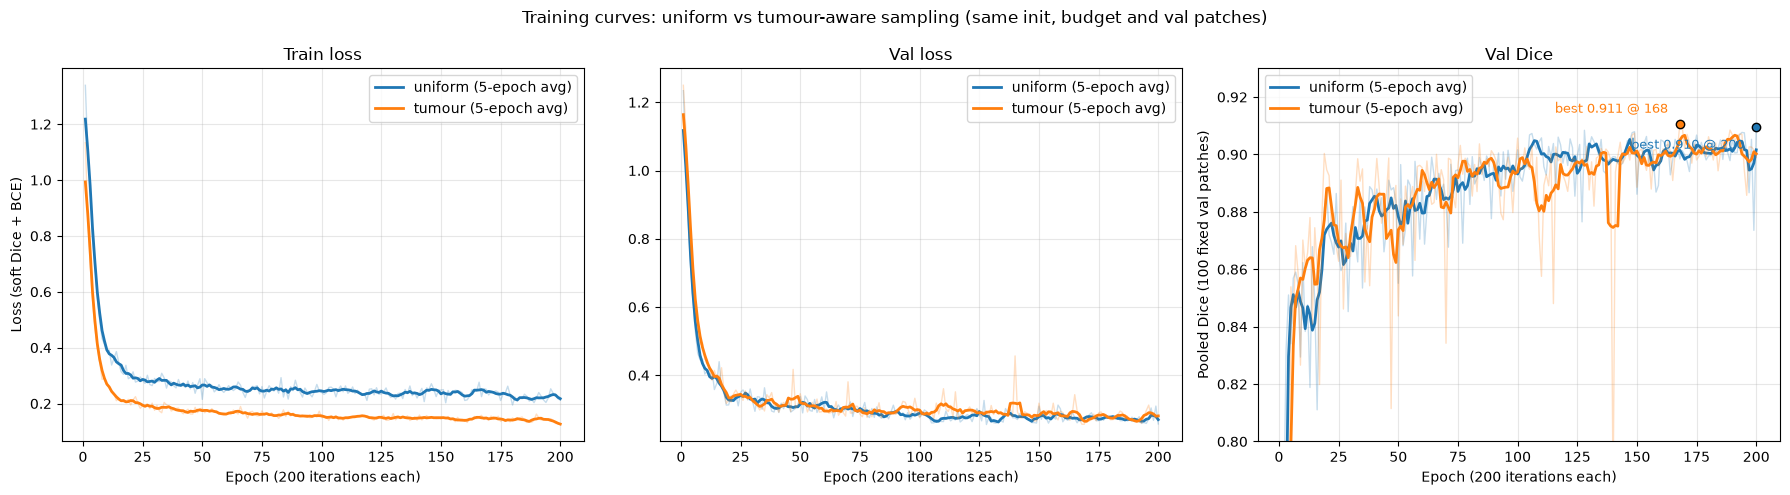

Saved: /home/mohamed.farrag/medass2/figures/training_curves.png


In [70]:
histories = {}
for name in ["uniform", "tumour"]:
    with open(RUNS_DIR / name / "history.json") as f:
        histories[name] = json.load(f)


def moving_average(values, window=5):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return values
    kernel = np.ones(window) / window
    padded = np.pad(values, (window // 2, window - 1 - window // 2), mode="edge")
    return np.convolve(padded, kernel, mode="valid")


colors = {"uniform": "tab:blue", "tumour": "tab:orange"}
panels = [("train_loss", "Train loss"), ("val_loss", "Val loss"), ("val_dice", "Val Dice")]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (key, title) in zip(axes, panels):
    for name, h in histories.items():
        epochs = np.array(h["epoch"])
        values = np.array(h[key])
        ax.plot(epochs, values, color=colors[name], alpha=0.25, linewidth=1)
        ax.plot(epochs, moving_average(values), color=colors[name], linewidth=2,
                label=f"{name} (5-epoch avg)")
    ax.set_title(title)
    ax.set_xlabel("Epoch (200 iterations each)")
    ax.grid(alpha=0.3)
    ax.legend()

for name, h in histories.items():
    best_epoch = int(np.argmax(h["val_dice"])) + 1
    best_dice = max(h["val_dice"])
    axes[2].scatter(best_epoch, best_dice, color=colors[name], edgecolor="black", zorder=5)
    axes[2].annotate(f"best {best_dice:.3f} @ {best_epoch}", (best_epoch, best_dice),
                     textcoords="offset points", xytext=(-90, 8 if name == "tumour" else -16),
                     fontsize=9, color=colors[name])

axes[0].set_ylabel("Loss (soft Dice + BCE)")
axes[2].set_ylabel("Pooled Dice (100 fixed val patches)")
axes[2].set_ylim(0.8, 0.93)

fig.suptitle("Training curves: uniform vs tumour-aware sampling (same init, budget and val patches)")
plt.tight_layout()

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", (FIG_DIR / "training_curves.png").resolve())

In [71]:
def window_starts(size, patch, stride):
    starts = list(range(0, size - patch + 1, stride))
    if starts[-1] != size - patch:
        starts.append(size - patch)
    return starts


@torch.no_grad()
def sliding_window_predict(model, image, patch=64, overlap=0.5, batch_size=8):
    model.eval()
    stride = int(patch * (1 - overlap))
    spatial = image.shape[1:]

    starts = [window_starts(s, patch, stride) for s in spatial]
    corners = [(a, b, c) for a in starts[0] for b in starts[1] for c in starts[2]]

    prob_sum = torch.zeros(spatial, dtype=torch.float32, device=device)
    count = torch.zeros(spatial, dtype=torch.float32, device=device)
    image_t = torch.as_tensor(np.asarray(image, dtype=np.float32), device=device)

    for i in range(0, len(corners), batch_size):
        batch_corners = corners[i:i + batch_size]
        x = torch.stack([image_t[:, a:a + patch, b:b + patch, c:c + patch]
                         for a, b, c in batch_corners])
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            logits = model(x)
        probs = torch.sigmoid(logits.float())[:, 0]
        for (a, b, c), p in zip(batch_corners, probs):
            prob_sum[a:a + patch, b:b + patch, c:c + patch] += p
            count[a:a + patch, b:b + patch, c:c + patch] += 1

    prob_cropped = (prob_sum / count).cpu().numpy()
    prob_full = uncrop(prob_cropped, crop_start, original_shape)
    return prob_full, {"n_windows": len(corners), "count_min": int(count.min().item()),
                       "stride": stride}


def load_model(checkpoint_path):
    m = UNet3D(in_channels=4, out_channels=1, base=16).to(device)
    ckpt = torch.load(checkpoint_path, map_location=device)
    m.load_state_dict(ckpt["model"])
    m.eval()
    return m, ckpt.get("epoch"), ckpt.get("val_dice")


def dice_score(pred, ref):
    total = pred.sum() + ref.sum()
    return 1.0 if total == 0 else 2.0 * np.logical_and(pred, ref).sum() / total


model, ckpt_epoch, ckpt_dice = load_model(RUNS_DIR / "uniform" / "best.pt")
print(f"Model: uniform best.pt (epoch {ckpt_epoch}, patch val Dice {ckpt_dice:.4f})")

voxel_ml = float(np.prod(ref_spacing)) / 1000.0

for case_id in val_ids[:3]:
    image = np.load(CACHE_DIR / f"{case_id}_img.npy")
    row = split_df.loc[split_df["case_id"] == case_id].iloc[0]
    ref = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj) > 0

    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    prob, info = sliding_window_predict(model, image, patch=64, overlap=0.5)
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - t0

    pred = prob > 0.5

    print(f"\n{case_id}")
    print(f"  windows: {info['n_windows']} | stride: {info['stride']} | time: {elapsed:.2f} s")
    print(f"  count.min(): {info['count_min']}")
    print(f"  prob shape: {prob.shape}")
    print(f"  Dice: {dice_score(pred, ref):.4f}")
    print(f"  Predicted volume: {pred.sum() * voxel_ml:.2f} mL | reference volume: {ref.sum() * voxel_ml:.2f} mL")

Model: uniform best.pt (epoch 200, patch val Dice 0.9097)

BRATS_006
  windows: 120 | stride: 32 | time: 0.37 s
  count.min(): 1
  prob shape: (240, 240, 155)
  Dice: 0.9363
  Predicted volume: 218.11 mL | reference volume: 217.36 mL

BRATS_019
  windows: 120 | stride: 32 | time: 0.23 s
  count.min(): 1
  prob shape: (240, 240, 155)
  Dice: 0.7932
  Predicted volume: 103.27 mL | reference volume: 149.34 mL

BRATS_020
  windows: 120 | stride: 32 | time: 0.23 s
  count.min(): 1
  prob shape: (240, 240, 155)
  Dice: 0.9214
  Predicted volume: 263.05 mL | reference volume: 256.87 mL


In [72]:
from scipy.stats import wilcoxon

SAMPLERS = ["uniform", "tumour"]
THRESHOLD = 0.5
voxel_ml = float(np.prod(ref_spacing)) / 1000.0


def case_metrics(pred, ref):
    tp = int(np.logical_and(pred, ref).sum())
    fp = int(np.logical_and(pred, ~ref).sum())
    fn = int(np.logical_and(~pred, ref).sum())
    return {
        "dice": dice_score(pred, ref),
        "sensitivity": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
        "fp_ml": fp * voxel_ml,
        "fn_ml": fn * voxel_ml,
        "pred_ml": int(pred.sum()) * voxel_ml,
        "ref_ml": int(ref.sum()) * voxel_ml,
        "empty_pred": bool(pred.sum() == 0),
    }


models = {}
for s in SAMPLERS:
    models[s], ep, vd = load_model(RUNS_DIR / s / "best.pt")
    print(f"{s}: best.pt from epoch {ep} (patch val Dice {vd:.4f})")

rows = []
t0 = time.time()
for i, case_id in enumerate(val_ids, start=1):
    image = np.load(CACHE_DIR / f"{case_id}_img.npy")
    label_path = DATA_ROOT / split_df.loc[split_df["case_id"] == case_id, "label_relpath"].iloc[0]
    ref = np.asarray(nib.load(label_path).dataobj) > 0

    for s in SAMPLERS:
        prob, _ = sliding_window_predict(models[s], image, patch=64, overlap=0.5)
        rows.append({"case_id": case_id, "sampler": s, **case_metrics(prob > THRESHOLD, ref)})

    if i % 10 == 0:
        print(f"{i}/{len(val_ids)} cases done ({time.time() - t0:.0f} s)")

val_results = pd.DataFrame(rows)
val_results.to_csv(RUNS_DIR / "val_full_volume_metrics.csv", index=False)
print(f"\nEvaluated {val_results['case_id'].nunique()} cases × {len(SAMPLERS)} samplers "
      f"in {time.time() - t0:.0f} s")

metric_cols = ["dice", "sensitivity", "fp_ml", "fn_ml"]
summary = val_results.groupby("sampler")[metric_cols].agg(["mean", "std", "median"]).round(4)
print("\nPer-sampler summary (73 validation cases, full volumes):")
print(summary.T.to_string())
print("\nEmpty predictions:", val_results.groupby("sampler")["empty_pred"].sum().to_dict())

paired = val_results.pivot(index="case_id", columns="sampler", values="dice")
diff = paired["tumour"] - paired["uniform"]
wins, losses, ties = int((diff > 0).sum()), int((diff < 0).sum()), int((diff == 0).sum())
print("\nPaired Dice comparison (tumour - uniform):")
print(f"  tumour better: {wins} | uniform better: {losses} | ties: {ties} (of {len(diff)})")
print(f"  mean difference: {diff.mean():+.4f} | median difference: {diff.median():+.4f}")
print(f"  Wilcoxon signed-rank p-value: {wilcoxon(paired['tumour'], paired['uniform']).pvalue:.4f}")

for metric in ["sensitivity", "fp_ml"]:
    p = val_results.pivot(index="case_id", columns="sampler", values=metric)
    d = p["tumour"] - p["uniform"]
    print(f"  {metric}: tumour higher in {int((d > 0).sum())} cases, lower in {int((d < 0).sum())}, "
          f"mean difference {d.mean():+.4f}")

uniform: best.pt from epoch 200 (patch val Dice 0.9097)
tumour: best.pt from epoch 168 (patch val Dice 0.9107)
10/73 cases done (8 s)
20/73 cases done (15 s)
30/73 cases done (23 s)
40/73 cases done (30 s)
50/73 cases done (38 s)
60/73 cases done (45 s)
70/73 cases done (53 s)

Evaluated 73 cases × 2 samplers in 55 s

Per-sampler summary (73 validation cases, full volumes):
sampler             tumour  uniform
dice        mean    0.9013   0.8858
            std     0.0565   0.0845
            median  0.9131   0.9093
sensitivity mean    0.8989   0.8699
            std     0.0817   0.1297
            median  0.9243   0.9179
fp_ml       mean    7.8430   7.0172
            std     8.6093   7.2128
            median  5.5440   4.4710
fn_ml       mean    8.9402  11.2221
            std     8.1562  11.7287
            median  6.6830   7.5770

Empty predictions: {'tumour': 0, 'uniform': 0}

Paired Dice comparison (tumour - uniform):
  tumour better: 55 | uniform better: 18 | ties: 0 (of 73)
  me

In [73]:
val_results = pd.read_csv(RUNS_DIR / "val_full_volume_metrics.csv")
paired = val_results.pivot(index="case_id", columns="sampler", values="dice")
diff = paired["tumour"] - paired["uniform"]
print("FN median (mL):", val_results.groupby("sampler")["fn_ml"].median().round(3).to_dict())
print("Empty predictions:", val_results.groupby("sampler")["empty_pred"].sum().to_dict())
print(f"Dice: tumour better in {int((diff > 0).sum())}, uniform better in {int((diff < 0).sum())}, "
      f"ties {int((diff == 0).sum())}")
print("Worst 5 uniform cases and tumour-aware Dice on them:")
print(paired.sort_values("uniform").head(5).round(4).to_string())

FN median (mL): {'tumour': 6.683, 'uniform': 7.577}
Empty predictions: {'tumour': 0, 'uniform': 0}
Dice: tumour better in 55, uniform better in 18, ties 0
Worst 5 uniform cases and tumour-aware Dice on them:
sampler    tumour  uniform
case_id                   
BRATS_077  0.6554   0.3916
BRATS_120  0.7932   0.6673
BRATS_363  0.7972   0.7575
BRATS_373  0.8014   0.7637
BRATS_136  0.8434   0.7671


In [74]:
from scipy import ndimage

FINAL_SAMPLER = "tumour"
CC_STRUCTURE = ndimage.generate_binary_structure(3, 3)
SPACING = tuple(float(s) for s in ref_spacing)
voxel_ml = float(np.prod(SPACING)) / 1000.0


def surface(mask):
    return mask & ~ndimage.binary_erosion(mask, border_value=0)


def hd95(pred, ref, spacing=SPACING, margin=2):
    if not pred.any() and not ref.any():
        return 0.0
    if not pred.any() or not ref.any():
        return np.nan
    union = pred | ref
    idx = np.argwhere(union)
    lo = np.maximum(idx.min(0) - margin, 0)
    hi = np.minimum(idx.max(0) + margin + 1, union.shape)
    box = tuple(slice(l, h) for l, h in zip(lo, hi))
    p_surf, r_surf = surface(pred[box]), surface(ref[box])
    dist_to_ref = ndimage.distance_transform_edt(~r_surf, sampling=spacing)
    dist_to_pred = ndimage.distance_transform_edt(~p_surf, sampling=spacing)
    distances = np.concatenate([dist_to_ref[p_surf], dist_to_pred[r_surf]])
    return float(np.percentile(distances, 95))


def full_metrics(pred, ref):
    tp = int(np.logical_and(pred, ref).sum())
    fp = int(np.logical_and(pred, ~ref).sum())
    fn = int(np.logical_and(~pred, ref).sum())
    pred_ml = (tp + fp) * voxel_ml
    ref_ml = (tp + fn) * voxel_ml
    return {
        "dice": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 1.0,
        "iou": tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 1.0,
        "sensitivity": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
        "hd95_mm": hd95(pred, ref),
        "pred_ml": pred_ml,
        "ref_ml": ref_ml,
        "abs_vol_err_ml": abs(pred_ml - ref_ml),
        "vol_err_pct": 100 * (pred_ml - ref_ml) / ref_ml if ref_ml > 0 else np.nan,
        "fp_ml": fp * voxel_ml,
        "fn_ml": fn * voxel_ml,
        "empty_pred": bool(tp + fp == 0),
        "n_components": int(ndimage.label(pred, structure=CC_STRUCTURE)[1]),
    }


def apply_cc_rule(pred, rule):
    if rule == "none" or not pred.any():
        return pred
    labels, n = ndimage.label(pred, structure=CC_STRUCTURE)
    sizes = np.bincount(labels.ravel())[1:]
    if rule == "largest":
        return labels == (np.argmax(sizes) + 1)
    if rule.startswith("min_"):
        min_voxels = int(round(float(rule.split("_")[1]) / voxel_ml))
        keep = np.flatnonzero(sizes >= min_voxels) + 1
        return np.isin(labels, keep)
    raise ValueError(rule)


CC_RULES = ["none", "largest", "min_0.1", "min_0.5"]

final_model, ep, vd = load_model(RUNS_DIR / FINAL_SAMPLER / "best.pt")
print(f"Frozen model: {FINAL_SAMPLER} best.pt (epoch {ep}), threshold {THRESHOLD}, "
      f"26-connectivity, spacing {SPACING}")

cc_rows, ref_rows = [], []
t0 = time.time()
for i, case_id in enumerate(val_ids, start=1):
    image = np.load(CACHE_DIR / f"{case_id}_img.npy")
    label_path = DATA_ROOT / split_df.loc[split_df["case_id"] == case_id, "label_relpath"].iloc[0]
    ref = np.asarray(nib.load(label_path).dataobj) > 0

    ref_labels, ref_n = ndimage.label(ref, structure=CC_STRUCTURE)
    ref_sizes = np.bincount(ref_labels.ravel())[1:] * voxel_ml
    ref_rows.append({"case_id": case_id, "ref_components": ref_n,
                     "ref_components_ge_0.1ml": int((ref_sizes >= 0.1).sum()),
                     "ref_largest_share": float(ref_sizes.max() / ref_sizes.sum())})

    prob, _ = sliding_window_predict(final_model, image, patch=64, overlap=0.5)
    pred = prob > THRESHOLD

    for rule in CC_RULES:
        cc_rows.append({"case_id": case_id, "rule": rule,
                        **full_metrics(apply_cc_rule(pred, rule), ref)})

    if i % 10 == 0:
        print(f"{i}/{len(val_ids)} cases done ({time.time() - t0:.0f} s)")

cc_val = pd.DataFrame(cc_rows)
ref_info = pd.DataFrame(ref_rows)
cc_val.to_csv(RUNS_DIR / "val_cc_rule_metrics.csv", index=False)

print("\nReference multifocality (validation):")
print(f"  cases with >1 reference component >= 0.1 mL: "
      f"{int((ref_info['ref_components_ge_0.1ml'] > 1).sum())} of {len(ref_info)}")
print(f"  largest reference component share of tumour volume: "
      f"median {ref_info['ref_largest_share'].median():.3f}, min {ref_info['ref_largest_share'].min():.3f}")

summary_cols = ["dice", "iou", "sensitivity", "hd95_mm", "abs_vol_err_ml", "vol_err_pct",
                "fp_ml", "fn_ml", "n_components"]
cc_summary = (cc_val.groupby("rule")[summary_cols].agg(["mean", "median"])
              .reindex(CC_RULES).round(3))
print("\nValidation metrics per CC rule (mean / median over 73 cases):")
print(cc_summary.T.to_string())
print("\nEmpty predictions per rule:", cc_val.groupby("rule")["empty_pred"].sum().reindex(CC_RULES).to_dict())
print("HD95 NaN count per rule:", cc_val.groupby("rule")["hd95_mm"].apply(lambda s: int(s.isna().sum()))
      .reindex(CC_RULES).to_dict())

base = cc_val[cc_val["rule"] == "none"].set_index("case_id")
for rule in CC_RULES[1:]:
    r = cc_val[cc_val["rule"] == rule].set_index("case_id")
    d_dice = r["dice"] - base["dice"]
    d_hd = r["hd95_mm"] - base["hd95_mm"]
    print(f"\n{rule} vs none:")
    print(f"  Dice up in {int((d_dice > 1e-6).sum())}, down in {int((d_dice < -1e-6).sum())}, "
          f"unchanged in {int((d_dice.abs() <= 1e-6).sum())} | mean change {d_dice.mean():+.4f}")
    print(f"  Dice drop > 0.01 (real tumour removed): {int((d_dice < -0.01).sum())} cases")
    print(f"  HD95 lower in {int((d_hd < -1e-6).sum())}, higher in {int((d_hd > 1e-6).sum())} | "
          f"mean change {d_hd.mean():+.2f} mm")
    print(f"  Mean sensitivity change: {(r['sensitivity'] - base['sensitivity']).mean():+.4f}")

Frozen model: tumour best.pt (epoch 168), threshold 0.5, 26-connectivity, spacing (1.0, 1.0, 1.0)
10/73 cases done (20 s)
20/73 cases done (40 s)
30/73 cases done (59 s)
40/73 cases done (78 s)
50/73 cases done (95 s)
60/73 cases done (113 s)
70/73 cases done (132 s)

Reference multifocality (validation):
  cases with >1 reference component >= 0.1 mL: 12 of 73
  largest reference component share of tumour volume: median 1.000, min 0.580

Validation metrics per CC rule (mean / median over 73 cases):
rule                    none  largest  min_0.1  min_0.5
dice           mean    0.901    0.893    0.901    0.902
               median  0.913    0.912    0.913    0.913
iou            mean    0.825    0.813    0.825    0.825
               median  0.840    0.838    0.840    0.840
sensitivity    mean    0.899    0.878    0.899    0.899
               median  0.924    0.918    0.924    0.924
hd95_mm        mean    5.819    8.274    5.847    5.818
               median  3.309    3.162    3.317  

In [75]:
cc_val = pd.read_csv(RUNS_DIR / "val_cc_rule_metrics.csv")
print(cc_val.groupby("rule")[["fp_ml", "fn_ml", "n_components"]].agg(["mean", "median"])
      .reindex(CC_RULES).round(3).T.to_string())
print("\nEmpty predictions:", cc_val.groupby("rule")["empty_pred"].sum().reindex(CC_RULES).to_dict())
print("HD95 NaN:", cc_val.groupby("rule")["hd95_mm"].apply(lambda s: int(s.isna().sum()))
      .reindex(CC_RULES).to_dict())

rule                  none  largest  min_0.1  min_0.5
fp_ml        mean    7.843    7.026    7.827    7.787
             median  5.544    4.042    5.532    5.477
fn_ml        mean    8.940   11.145    8.946    8.951
             median  6.683    7.145    6.683    6.683
n_components mean    3.096    1.000    1.548    1.370
             median  2.000    1.000    1.000    1.000

Empty predictions: {'none': 0, 'largest': 0, 'min_0.1': 0, 'min_0.5': 0}
HD95 NaN: {'none': 0, 'largest': 0, 'min_0.1': 0, 'min_0.5': 0}


In [76]:
TEST_FLAG = RUNS_DIR / "test_evaluated.flag"
assert not TEST_FLAG.exists(), "Test set already evaluated, load runs/test_metrics.csv instead of re-running"

test_df = split_df[split_df["split"] == "test"].reset_index(drop=True)
TEST_RULES = ["none", "min_0.5"]

final_model, ep, vd = load_model(RUNS_DIR / FINAL_SAMPLER / "best.pt")
print(f"Frozen pipeline: {FINAL_SAMPLER} best.pt (epoch {ep}) | threshold {THRESHOLD} | "
      f"window 64, stride 32, uniform averaging | official rule: none | test cases: {len(test_df)}")

test_rows = []
t0 = time.time()
for i, row in test_df.iterrows():
    image, _ = preprocess_case(DATA_ROOT / row["image_relpath"], None, crop_start, crop_size)
    prob, _ = sliding_window_predict(final_model, image, patch=64, overlap=0.5)
    pred = prob > THRESHOLD

    ref = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj) > 0

    for rule in TEST_RULES:
        test_rows.append({"case_id": row["case_id"], "rule": rule,
                          **full_metrics(apply_cc_rule(pred, rule), ref)})

    if (i + 1) % 10 == 0:
        print(f"{i + 1}/{len(test_df)} cases done ({time.time() - t0:.0f} s)")

test_results = pd.DataFrame(test_rows)
test_results.to_csv(RUNS_DIR / "test_metrics.csv", index=False)
TEST_FLAG.write_text(f"evaluated {time.ctime()} with {FINAL_SAMPLER} best.pt epoch {ep}, rule none\n")
print(f"\nSaved per-case results: {(RUNS_DIR / 'test_metrics.csv').resolve()}")

overlap_cols = ["dice", "iou", "sensitivity", "hd95_mm"]
print("\nTest overlap metrics (73 cases): mean / SD / median")
print(test_results.groupby("rule")[overlap_cols].agg(["mean", "std", "median"])
      .reindex(TEST_RULES).round(4).T.to_string())
print("\nEmpty predictions:", test_results.groupby("rule")["empty_pred"].sum().reindex(TEST_RULES).to_dict())
print("HD95 NaN:", test_results.groupby("rule")["hd95_mm"].apply(lambda s: int(s.isna().sum()))
      .reindex(TEST_RULES).to_dict())

vol_cols = ["pred_ml", "abs_vol_err_ml", "vol_err_pct"]
print("\nTest volume metrics: mean / SD / median")
print(test_results.groupby("rule")[vol_cols].agg(["mean", "std", "median"])
      .reindex(TEST_RULES).round(3).T.to_string())

official = test_results[test_results["rule"] == "none"]
print("\nMean absolute % volume error (official rule):", f"{official['vol_err_pct'].abs().mean():.2f}%")
print("Cases over-segmented / under-segmented:",
      int((official["vol_err_pct"] > 0).sum()), "/", int((official["vol_err_pct"] < 0).sum()))

per_case_volume = official[["case_id", "ref_ml", "pred_ml", "abs_vol_err_ml", "vol_err_pct"]].round(2)
per_case_volume.to_csv(RUNS_DIR / "test_volume_per_case.csv", index=False)
print("\nPer-case volume (first 10 of 73, full table in runs/test_volume_per_case.csv):")
print(per_case_volume.head(10).to_string(index=False))

ref_vol = official["ref_ml"]
print("\nTest reference tumour volume (mL):")
print(f"  mean {ref_vol.mean():.2f} | median {ref_vol.median():.2f} | "
      f"min {ref_vol.min():.2f} | max {ref_vol.max():.2f} | SD {ref_vol.std():.2f}")

Frozen pipeline: tumour best.pt (epoch 168) | threshold 0.5 | window 64, stride 32, uniform averaging | official rule: none | test cases: 73
10/73 cases done (20 s)
20/73 cases done (42 s)
30/73 cases done (63 s)
40/73 cases done (84 s)
50/73 cases done (105 s)
60/73 cases done (125 s)
70/73 cases done (146 s)

Saved per-case results: /home/mohamed.farrag/medass2/runs/test_metrics.csv

Test overlap metrics (73 cases): mean / SD / median
rule                  none  min_0.5
dice        mean    0.9059   0.9065
            std     0.0560   0.0547
            median  0.9245   0.9245
iou         mean    0.8324   0.8332
            std     0.0872   0.0857
            median  0.8595   0.8595
sensitivity mean    0.8944   0.8943
            std     0.0725   0.0727
            median  0.9135   0.9135
hd95_mm     mean    5.7231   6.0183
            std     7.1730   7.8205
            median  3.0000   3.0000

Empty predictions: {'none': 0, 'min_0.5': 0}
HD95 NaN: {'none': 0, 'min_0.5': 0}

Test vol

In [77]:
test_results = pd.read_csv(RUNS_DIR / "test_metrics.csv")
official = test_results[test_results["rule"] == "none"]
print("Empty predictions:", test_results.groupby("rule")["empty_pred"].sum().to_dict())
print("HD95 NaN:", test_results.groupby("rule")["hd95_mm"].apply(lambda s: int(s.isna().sum())).to_dict())
print(official[["pred_ml", "abs_vol_err_ml", "vol_err_pct"]].agg(["mean", "std", "median"]).round(2).to_string())
print(f"Mean |% error|: {official['vol_err_pct'].abs().mean():.2f}% | median |% error|: "
      f"{official['vol_err_pct'].abs().median():.2f}%")
print("Over / under-segmented:", int((official["vol_err_pct"] > 0).sum()), "/",
      int((official["vol_err_pct"] < 0).sum()))
print("HD95 > 10 mm:", int((official["hd95_mm"] > 10).sum()), "cases")

Empty predictions: {'min_0.5': 0, 'none': 0}
HD95 NaN: {'min_0.5': 0, 'none': 0}
        pred_ml  abs_vol_err_ml  vol_err_pct
mean     104.30            8.76        -2.48
std       64.43            8.13        11.96
median    87.20            7.13        -3.30
Mean |% error|: 9.48% | median |% error|: 8.00%
Over / under-segmented: 24 / 49
HD95 > 10 mm: 6 cases


Test set, 73 cases: mean ± SD (median)
                 Metric    No rule (official)       Remove < 0.5 mL
                   Dice 0.906 ± 0.056 (0.924) 0.907 ± 0.055 (0.924)
                    IoU 0.832 ± 0.087 (0.860) 0.833 ± 0.086 (0.860)
            Sensitivity 0.894 ± 0.073 (0.913) 0.894 ± 0.073 (0.913)
              HD95 (mm)    5.72 ± 7.17 (3.00)    6.02 ± 7.82 (3.00)
 Abs. volume error (mL)    8.76 ± 8.13 (7.13)    8.77 ± 8.14 (7.13)
  Abs. volume error (%)    9.48 ± 7.63 (8.00)    9.39 ± 7.62 (7.09)
Signed volume error (%) -2.48 ± 11.96 (-3.30) -2.66 ± 11.84 (-3.36)
      Empty predictions                     0                     0

Markdown version for the report:

| Metric                  | No rule (official)    | Remove < 0.5 mL       |
|:------------------------|:----------------------|:----------------------|
| Dice                    | 0.906 ± 0.056 (0.924) | 0.907 ± 0.055 (0.924) |
| IoU                     | 0.832 ± 0.087 (0.860) | 0.833 ± 0.086 (0.860) |
| Sensitiv

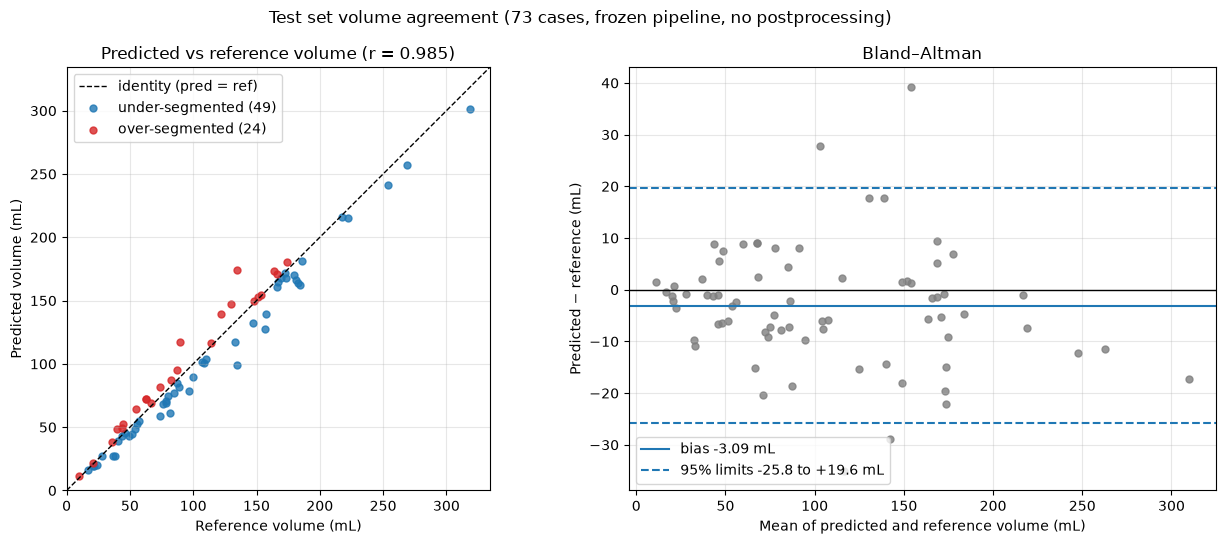

Bias: -3.09 mL | 95% limits of agreement: -25.79 to +19.61 mL | r = 0.985
Saved: /home/mohamed.farrag/medass2/figures/test_volume_agreement.png


In [79]:
test_results = pd.read_csv(RUNS_DIR / "test_metrics.csv")
test_results["abs_vol_err_pct"] = test_results["vol_err_pct"].abs()

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

table_metrics = [("dice", "Dice", 3), ("iou", "IoU", 3), ("sensitivity", "Sensitivity", 3),
                 ("hd95_mm", "HD95 (mm)", 2), ("abs_vol_err_ml", "Abs. volume error (mL)", 2),
                 ("abs_vol_err_pct", "Abs. volume error (%)", 2), ("vol_err_pct", "Signed volume error (%)", 2)]
rule_names = {"none": "No rule (official)", "min_0.5": "Remove < 0.5 mL"}

table_rows = []
for col, name, d in table_metrics:
    entry = {"Metric": name}
    for rule, label in rule_names.items():
        s = test_results.loc[test_results["rule"] == rule, col]
        entry[label] = f"{s.mean():.{d}f} ± {s.std():.{d}f} ({s.median():.{d}f})"
    table_rows.append(entry)
entry = {"Metric": "Empty predictions"}
for rule, label in rule_names.items():
    entry[label] = str(int(test_results.loc[test_results["rule"] == rule, "empty_pred"].sum()))
table_rows.append(entry)

before_after = pd.DataFrame(table_rows)
before_after.to_csv(RUNS_DIR / "test_before_after_cc.csv", index=False)
print("Test set, 73 cases: mean ± SD (median)")
print(before_after.to_string(index=False))
print("\nMarkdown version for the report:\n")
print(before_after.to_markdown(index=False))

official = test_results[test_results["rule"] == "none"].copy()
per_case = official[["case_id", "ref_ml", "pred_ml", "abs_vol_err_ml", "vol_err_pct"]].round(2)
per_case = per_case.sort_values("case_id").reset_index(drop=True)
per_case.to_csv(RUNS_DIR / "test_volume_per_case.csv", index=False)
with open(RUNS_DIR / "test_volume_per_case.md", "w") as f:
    f.write(per_case.to_markdown(index=False))
print(f"\nPer-case table ({len(per_case)} rows) saved to runs/test_volume_per_case.csv and .md")

ref_v = official["ref_ml"].to_numpy()
pred_v = official["pred_ml"].to_numpy()
diff = pred_v - ref_v
mean_v = (pred_v + ref_v) / 2
bias = diff.mean()
loa = 1.96 * diff.std(ddof=1)
r = np.corrcoef(ref_v, pred_v)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
lim = [0, max(ref_v.max(), pred_v.max()) * 1.05]
ax.plot(lim, lim, "k--", linewidth=1, label="identity (pred = ref)")
under = pred_v < ref_v
ax.scatter(ref_v[under], pred_v[under], s=25, color="tab:blue", alpha=0.8,
           label=f"under-segmented ({under.sum()})")
ax.scatter(ref_v[~under], pred_v[~under], s=25, color="tab:red", alpha=0.8,
           label=f"over-segmented ({(~under).sum()})")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_aspect("equal")
ax.set_xlabel("Reference volume (mL)")
ax.set_ylabel("Predicted volume (mL)")
ax.set_title(f"Predicted vs reference volume (r = {r:.3f})")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

ax = axes[1]
ax.scatter(mean_v, diff, s=25, color="tab:gray", alpha=0.8)
ax.axhline(0, color="black", linewidth=1)
ax.axhline(bias, color="tab:blue", linestyle="-", label=f"bias {bias:+.2f} mL")
ax.axhline(bias + loa, color="tab:blue", linestyle="--",
           label=f"95% limits {bias - loa:+.1f} to {bias + loa:+.1f} mL")
ax.axhline(bias - loa, color="tab:blue", linestyle="--")
ax.set_xlabel("Mean of predicted and reference volume (mL)")
ax.set_ylabel("Predicted − reference (mL)")
ax.set_title("Bland–Altman")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)

fig.suptitle("Test set volume agreement (73 cases, frozen pipeline, no postprocessing)")
plt.tight_layout()
fig.savefig(FIG_DIR / "test_volume_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Bias: {bias:+.2f} mL | 95% limits of agreement: {bias - loa:+.2f} to {bias + loa:+.2f} mL | r = {r:.3f}")
print("Saved:", (FIG_DIR / "test_volume_agreement.png").resolve())

Test set, 73 cases: mean ± SD (median)
                 Metric    No rule (official)       Remove < 0.5 mL
                   Dice 0.906 ± 0.056 (0.924) 0.907 ± 0.055 (0.924)
                    IoU 0.832 ± 0.087 (0.860) 0.833 ± 0.086 (0.860)
            Sensitivity 0.894 ± 0.073 (0.913) 0.894 ± 0.073 (0.913)
              HD95 (mm)    5.72 ± 7.17 (3.00)    6.02 ± 7.82 (3.00)
 Abs. volume error (mL)    8.76 ± 8.13 (7.13)    8.77 ± 8.14 (7.13)
  Abs. volume error (%)    9.48 ± 7.63 (8.00)    9.39 ± 7.62 (7.09)
Signed volume error (%) -2.48 ± 11.96 (-3.30) -2.66 ± 11.84 (-3.36)
      Empty predictions                     0                     0

Saved 73-row per-case table: /home/mohamed.farrag/medass2/runs/test_volume_per_case.csv


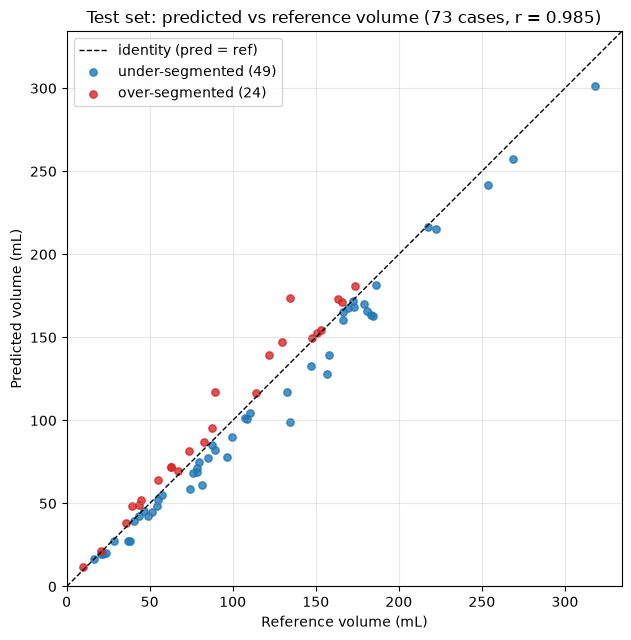

Saved: /home/mohamed.farrag/medass2/figures/test_volume_scatter.png

Volume agreement by tumour size (tertiles of reference volume):
             n ref_range  signed_pct  abs_pct  abs_ml  under  dice
size_group                                                        
small       25     10–67       -0.82    10.69    4.46     15  0.89
medium      24    74–135       -2.96    12.66   12.74     16  0.90
large       24   147–318       -3.73     5.04    9.24     18  0.94

Correlation of signed % error with reference volume: -0.054
Largest |% errors|:
  case_id  ref_ml  pred_ml  vol_err_pct  dice
BRATS_366   89.19   117.08        31.27  0.77
BRATS_241  134.58   173.88        29.20  0.85
BRATS_462   38.31    27.47       -28.30  0.80
BRATS_453  134.27    99.15       -26.15  0.84
BRATS_039   37.01    27.38       -26.03  0.83


In [80]:
test_results = pd.read_csv(RUNS_DIR / "test_metrics.csv")
test_results["abs_vol_err_pct"] = test_results["vol_err_pct"].abs()
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

table_metrics = [("dice", "Dice", 3), ("iou", "IoU", 3), ("sensitivity", "Sensitivity", 3),
                 ("hd95_mm", "HD95 (mm)", 2), ("abs_vol_err_ml", "Abs. volume error (mL)", 2),
                 ("abs_vol_err_pct", "Abs. volume error (%)", 2), ("vol_err_pct", "Signed volume error (%)", 2)]
rule_names = {"none": "No rule (official)", "min_0.5": "Remove < 0.5 mL"}

table_rows = []
for col, name, d in table_metrics:
    entry = {"Metric": name}
    for rule, label in rule_names.items():
        s = test_results.loc[test_results["rule"] == rule, col]
        entry[label] = f"{s.mean():.{d}f} ± {s.std():.{d}f} ({s.median():.{d}f})"
    table_rows.append(entry)
table_rows.append({"Metric": "Empty predictions",
                   **{label: str(int(test_results.loc[test_results["rule"] == rule, "empty_pred"].sum()))
                      for rule, label in rule_names.items()}})
before_after = pd.DataFrame(table_rows)
before_after.to_csv(RUNS_DIR / "test_before_after_cc.csv", index=False)
print("Test set, 73 cases: mean ± SD (median)")
print(before_after.to_string(index=False))

official = test_results[test_results["rule"] == "none"].copy()
per_case = (official[["case_id", "ref_ml", "pred_ml", "abs_vol_err_ml", "vol_err_pct"]]
            .round(2).sort_values("case_id").reset_index(drop=True))
per_case.to_csv(RUNS_DIR / "test_volume_per_case.csv", index=False)
print(f"\nSaved {len(per_case)}-row per-case table: {(RUNS_DIR / 'test_volume_per_case.csv').resolve()}")

ref_v = official["ref_ml"].to_numpy()
pred_v = official["pred_ml"].to_numpy()
under = pred_v < ref_v
r = np.corrcoef(ref_v, pred_v)[0, 1]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
lim = [0, max(ref_v.max(), pred_v.max()) * 1.05]
ax.plot(lim, lim, "k--", linewidth=1, label="identity (pred = ref)")
ax.scatter(ref_v[under], pred_v[under], s=28, color="tab:blue", alpha=0.8,
           label=f"under-segmented ({under.sum()})")
ax.scatter(ref_v[~under], pred_v[~under], s=28, color="tab:red", alpha=0.8,
           label=f"over-segmented ({(~under).sum()})")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_aspect("equal")
ax.set_xlabel("Reference volume (mL)")
ax.set_ylabel("Predicted volume (mL)")
ax.set_title(f"Test set: predicted vs reference volume (73 cases, r = {r:.3f})")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG_DIR / "test_volume_scatter.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", (FIG_DIR / "test_volume_scatter.png").resolve())

official["size_group"] = pd.qcut(official["ref_ml"], 3, labels=["small", "medium", "large"])
by_size = official.groupby("size_group", observed=True).agg(
    n=("case_id", "count"),
    ref_range=("ref_ml", lambda s: f"{s.min():.0f}–{s.max():.0f}"),
    signed_pct=("vol_err_pct", "mean"),
    abs_pct=("abs_vol_err_pct", "mean"),
    abs_ml=("abs_vol_err_ml", "mean"),
    under=("vol_err_pct", lambda s: int((s < 0).sum())),
    dice=("dice", "mean")).round(2)
print("\nVolume agreement by tumour size (tertiles of reference volume):")
print(by_size.to_string())
print(f"\nCorrelation of signed % error with reference volume: "
      f"{np.corrcoef(official['ref_ml'], official['vol_err_pct'])[0, 1]:+.3f}")
print("Largest |% errors|:")
print(official.reindex(official["abs_vol_err_pct"].sort_values(ascending=False).index)
      [["case_id", "ref_ml", "pred_ml", "vol_err_pct", "dice"]].head(5).round(2).to_string(index=False))

In [81]:
test_results = pd.read_csv(RUNS_DIR / "test_metrics.csv")
official = (test_results[test_results["rule"] == "none"]
            .sort_values("dice", ascending=False).reset_index(drop=True))

best_case = official.iloc[0]
median_case = official.iloc[len(official) // 2]
worst_case = official.iloc[-1]

g_cases = pd.DataFrame([best_case, median_case, worst_case])
g_cases.insert(0, "role", ["best", "median", "worst"])
show_cols = ["role", "case_id", "dice", "iou", "sensitivity", "hd95_mm",
             "ref_ml", "pred_ml", "vol_err_pct", "fp_ml", "fn_ml", "n_components"]
print("Section G cases (by Dice, official rule, test set):")
print(g_cases[show_cols].round(3).to_string(index=False))
print(f"\nMedian Dice of all 73: {official['dice'].median():.4f} "
      f"| selected median case Dice: {median_case['dice']:.4f} (rank {len(official) // 2 + 1} of {len(official)})")

decent = official[official["dice"] >= official["dice"].median()].copy()
decent["abs_vol_err_pct"] = decent["vol_err_pct"].abs()
extra = decent.sort_values("abs_vol_err_pct", ascending=False).head(3)
print("\nExtra candidates: Dice at or above the median but the largest volume errors")
print(extra[["case_id", "dice", "hd95_mm", "ref_ml", "pred_ml", "vol_err_pct"]].round(3).to_string(index=False))

g_cases.to_csv(RUNS_DIR / "section_g_cases.csv", index=False)

Section G cases (by Dice, official rule, test set):
  role   case_id  dice   iou  sensitivity  hd95_mm  ref_ml  pred_ml  vol_err_pct  fp_ml  fn_ml  n_components
  best BRATS_112 0.976 0.953        0.972    1.414 169.185  167.771       -0.836  3.339  4.753             3
median BRATS_440 0.924 0.860        0.941    2.000  66.816   69.275        3.680  6.369  3.910             1
 worst BRATS_376 0.697 0.534        0.746   25.000  10.101   11.527       14.117  3.995  2.569            14

Median Dice of all 73: 0.9245 | selected median case Dice: 0.9245 (rank 37 of 73)

Extra candidates: Dice at or above the median but the largest volume errors
  case_id  dice  hd95_mm  ref_ml  pred_ml  vol_err_pct
BRATS_158 0.926    3.000  49.235   42.689      -13.295
BRATS_144 0.926    5.916  51.296   44.833      -12.599
BRATS_467 0.935    2.236 157.749  139.682      -11.453


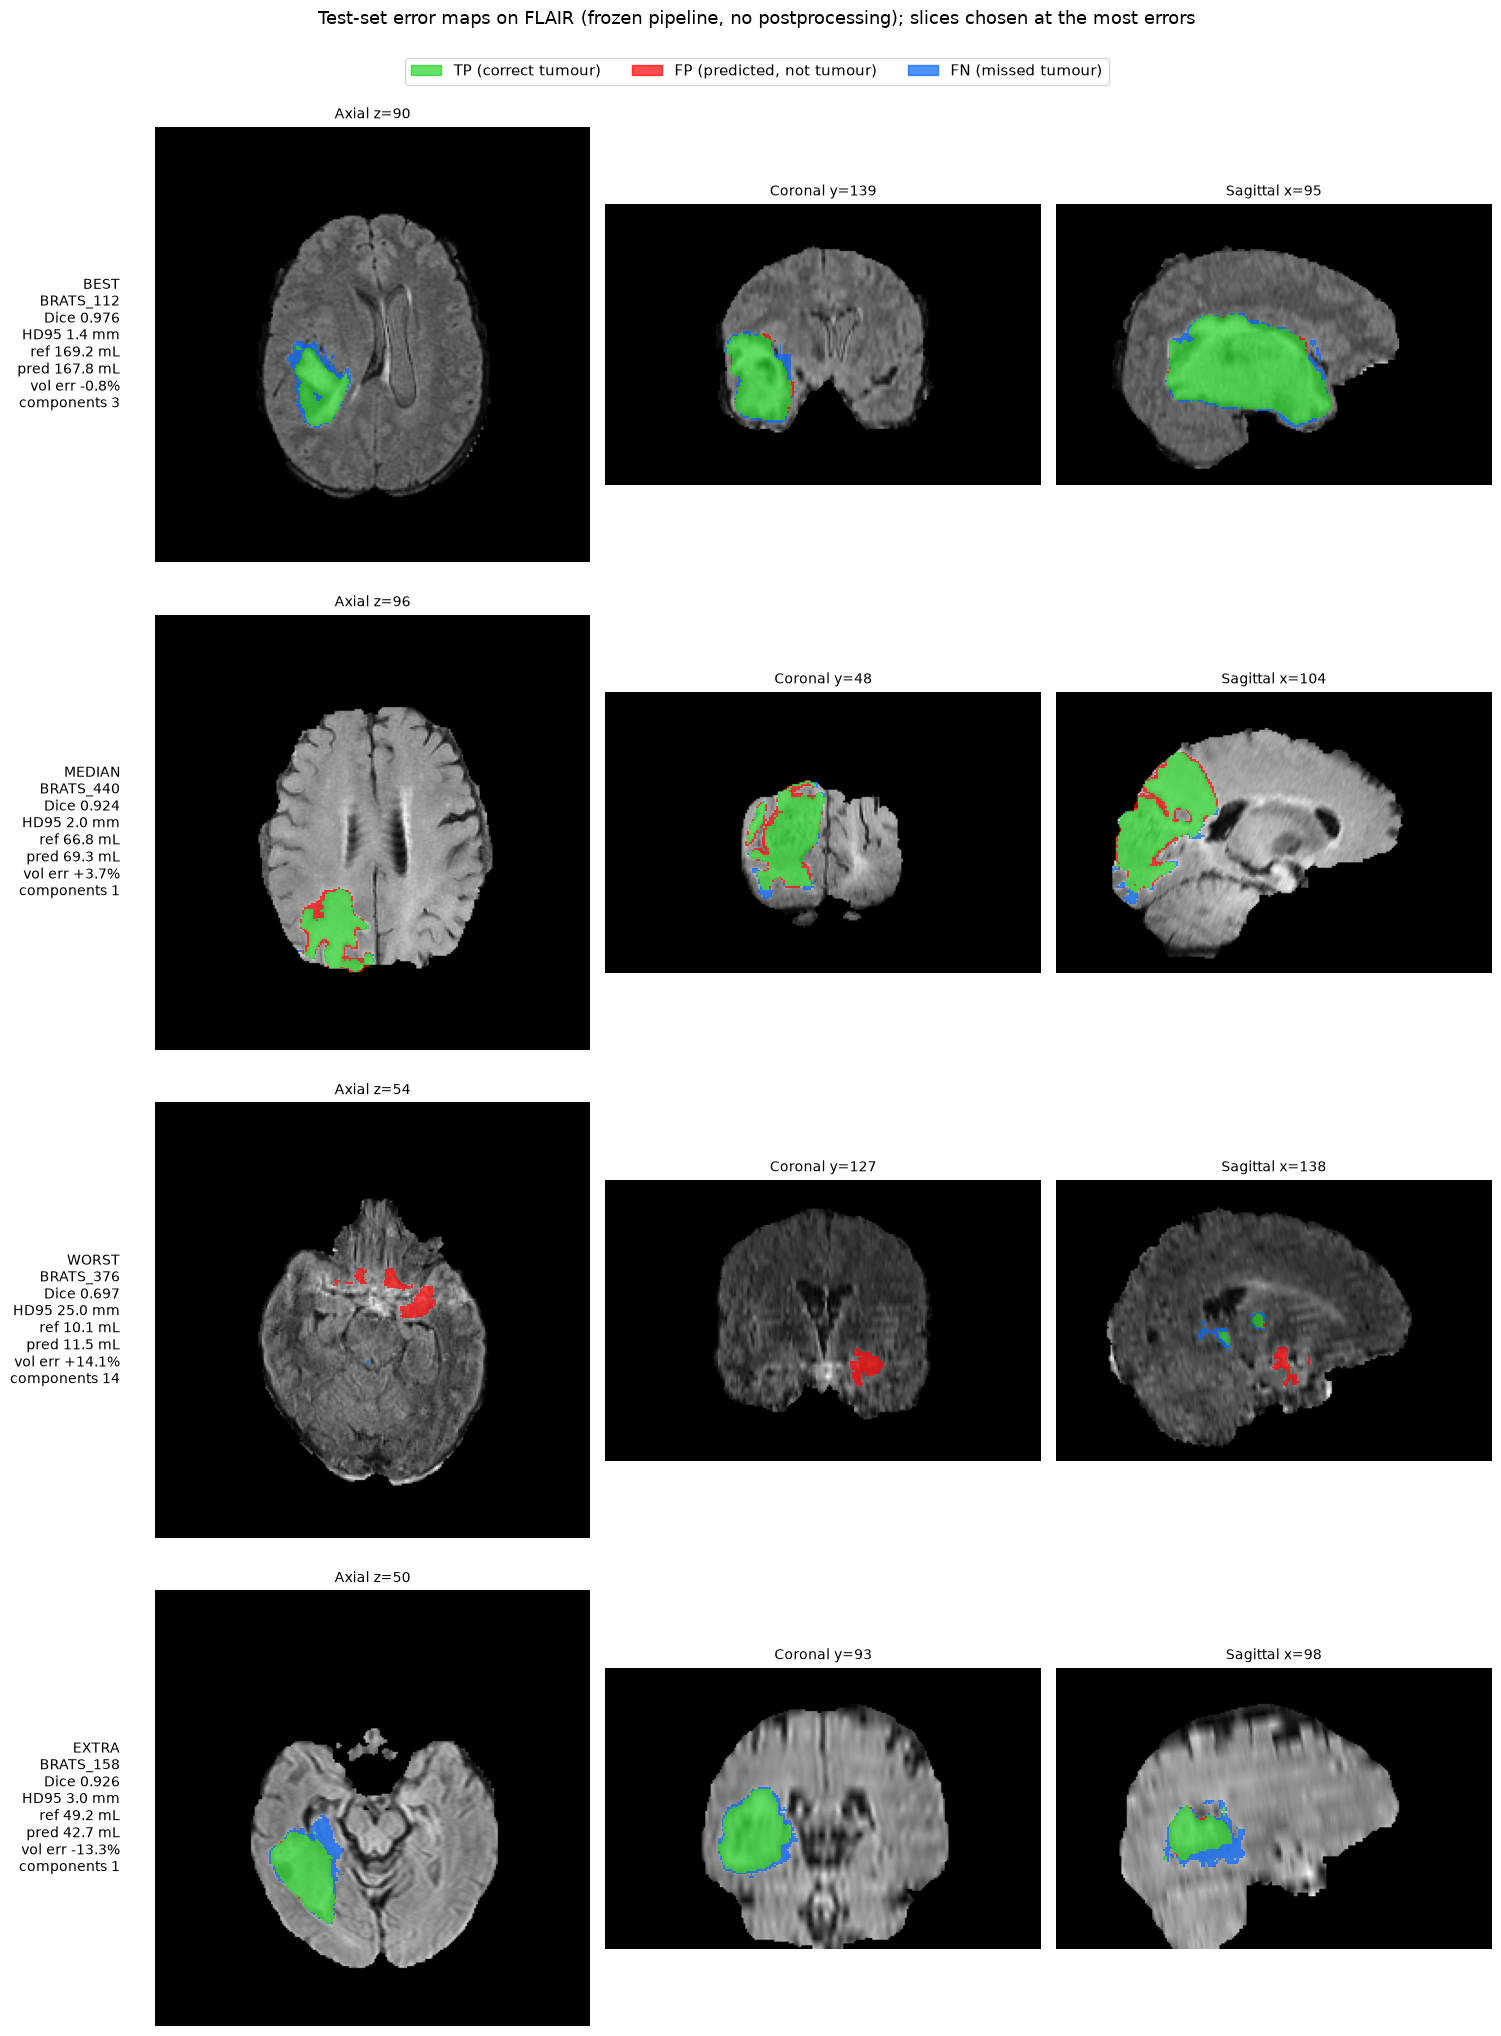

Saved: /home/mohamed.farrag/medass2/figures/section_g_error_maps.png


In [82]:
G_CASES = [("best", "BRATS_112"), ("median", "BRATS_440"), ("worst", "BRATS_376"), ("extra", "BRATS_158")]

final_model, ep, _ = load_model(RUNS_DIR / FINAL_SAMPLER / "best.pt")
saved = pd.read_csv(RUNS_DIR / "test_metrics.csv")
saved = saved[saved["rule"] == "none"].set_index("case_id")

colors = {"TP": (0.0, 0.8, 0.0, 0.6), "FP": (1.0, 0.0, 0.0, 0.7), "FN": (0.0, 0.4, 1.0, 0.7)}


def error_overlay(tp, fp, fn):
    rgba = np.zeros(tp.shape + (4,), dtype=float)
    for mask, key in [(tp, "TP"), (fp, "FP"), (fn, "FN")]:
        rgba[mask] = colors[key]
    return rgba


def pick_slice(error, union, axis):
    other = tuple(a for a in range(3) if a != axis)
    counts = error.sum(axis=other)
    if counts.max() == 0:
        counts = union.sum(axis=other)
    return int(np.argmax(counts))


fig, axes = plt.subplots(len(G_CASES), 3, figsize=(15, 5 * len(G_CASES)))

for r, (role, case_id) in enumerate(G_CASES):
    row = split_df.loc[split_df["case_id"] == case_id].iloc[0]
    image, _ = preprocess_case(DATA_ROOT / row["image_relpath"], None, crop_start, crop_size)
    prob, _ = sliding_window_predict(final_model, image, patch=64, overlap=0.5)
    pred = prob > THRESHOLD
    ref = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj) > 0
    flair = np.asarray(nib.load(DATA_ROOT / row["image_relpath"]).dataobj)[..., 0]

    tp, fp, fn = pred & ref, pred & ~ref, ~pred & ref
    error, union = fp | fn, pred | ref

    x = pick_slice(error, union, 0)
    y = pick_slice(error, union, 1)
    z = pick_slice(error, union, 2)

    views = [(f"Axial z={z}", np.s_[:, :, z]),
             (f"Coronal y={y}", np.s_[:, y, :]),
             (f"Sagittal x={x}", np.s_[x, :, :])]

    m = saved.loc[case_id]
    for c, (title, sl) in enumerate(views):
        ax = axes[r, c]
        ax.imshow(flair[sl].T, cmap="gray", origin="lower")
        ax.imshow(np.transpose(error_overlay(tp[sl], fp[sl], fn[sl]), (1, 0, 2)), origin="lower",
                  interpolation="nearest")
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    axes[r, 0].text(-0.08, 0.5,
                    f"{role.upper()}\n{case_id}\nDice {m['dice']:.3f}\nHD95 {m['hd95_mm']:.1f} mm\n"
                    f"ref {m['ref_ml']:.1f} mL\npred {m['pred_ml']:.1f} mL\n"
                    f"vol err {m['vol_err_pct']:+.1f}%\ncomponents {int(m['n_components'])}",
                    transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=10)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors[k]) for k in ["TP", "FP", "FN"]]
fig.legend(handles, ["TP (correct tumour)", "FP (predicted, not tumour)", "FN (missed tumour)"],
           loc="upper center", ncol=3, fontsize=11, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Test-set error maps on FLAIR (frozen pipeline, no postprocessing); slices chosen at the most errors",
             y=1.02, fontsize=13)
plt.tight_layout()
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "section_g_error_maps.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved:", (FIG_DIR / "section_g_error_maps.png").resolve())

In [83]:
row = split_df.loc[split_df["case_id"] == "BRATS_376"].iloc[0]
image, _ = preprocess_case(DATA_ROOT / row["image_relpath"], None, crop_start, crop_size)
prob, _ = sliding_window_predict(final_model, image, patch=64, overlap=0.5)
pred = prob > THRESHOLD
ref = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj) > 0

dist_to_ref = ndimage.distance_transform_edt(~ref, sampling=SPACING)
labels, n = ndimage.label(pred, structure=CC_STRUCTURE)
comp = pd.DataFrame([{"component": k,
                      "size_ml": (labels == k).sum() * voxel_ml,
                      "overlaps_ref": bool((ref & (labels == k)).any()),
                      "min_dist_to_ref_mm": dist_to_ref[labels == k].min(),
                      "max_dist_to_ref_mm": dist_to_ref[labels == k].max()}
                     for k in range(1, n + 1)]).sort_values("size_ml", ascending=False)
print(comp.round(2).to_string(index=False))
print(f"\nFP volume in components not touching the reference: "
      f"{comp.loc[~comp['overlaps_ref'], 'size_ml'].sum():.2f} mL")

 component  size_ml  overlaps_ref  min_dist_to_ref_mm  max_dist_to_ref_mm
         4     8.24          True                0.00               11.09
        10     1.98         False                9.27               31.32
         8     0.50          True                0.00                1.00
         7     0.44         False               14.35               27.50
         2     0.25         False               13.64               24.00
        12     0.08         False               25.81               31.54
         1     0.01         False               26.55               29.43
         9     0.01         False               17.38               18.55
         6     0.00         False               14.46               14.87
         5     0.00         False                4.47                5.39
        14     0.00         False               31.97               32.76
        11     0.00         False               26.48               27.39
         3     0.00         False     

In [84]:
CONDITIONS = [("full", None)] + [(f"no_{modality_map[str(c)]}", c) for c in range(4)]

final_model, ep, _ = load_model(RUNS_DIR / FINAL_SAMPLER / "best.pt")
print(f"Frozen model: {FINAL_SAMPLER} best.pt (epoch {ep}) | threshold {THRESHOLD} | no postprocessing")
print("Conditions:", [name for name, _ in CONDITIONS])

mm_rows = []
t0 = time.time()
for i, row in test_df.iterrows():
    image, _ = preprocess_case(DATA_ROOT / row["image_relpath"], None, crop_start, crop_size)
    ref = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj) > 0

    for name, ch in CONDITIONS:
        x = image.copy()
        if ch is not None:
            x[ch] = 0.0
        prob, _ = sliding_window_predict(final_model, x, patch=64, overlap=0.5)
        mm_rows.append({"case_id": row["case_id"], "condition": name,
                        **full_metrics(prob > THRESHOLD, ref)})

    if (i + 1) % 10 == 0:
        print(f"{i + 1}/{len(test_df)} cases done ({time.time() - t0:.0f} s)")

mm = pd.DataFrame(mm_rows)
mm.to_csv(RUNS_DIR / "bonus_missing_modality_test.csv", index=False)
cond_order = [name for name, _ in CONDITIONS]

saved_full = pd.read_csv(RUNS_DIR / "test_metrics.csv")
saved_full = saved_full[saved_full["rule"] == "none"].set_index("case_id")["dice"]
check = mm[mm["condition"] == "full"].set_index("case_id")["dice"]
print(f"\nFull-condition Dice matches saved test result: "
      f"{np.allclose(check.loc[saved_full.index], saved_full, atol=1e-6)}")

cols = ["dice", "sensitivity", "hd95_mm", "abs_vol_err_ml", "vol_err_pct"]
summary = mm.groupby("condition")[cols].agg(["mean", "median"]).reindex(cond_order)
print("\nMissing-modality stress test, 73 test cases (mean / median):")
print(summary.round(3).to_string())

full = mm[mm["condition"] == "full"].set_index("case_id")
rows = []
for name in cond_order[1:]:
    cur = mm[mm["condition"] == name].set_index("case_id")
    d_dice = cur["dice"] - full["dice"]
    rows.append({
        "condition": name,
        "mean_dice": cur["dice"].mean(),
        "delta_dice": d_dice.mean(),
        "dice_drop_cases": int((d_dice < -1e-6).sum()),
        "dice_drop_gt_0.05": int((d_dice < -0.05).sum()),
        "delta_sens": (cur["sensitivity"] - full["sensitivity"]).mean(),
        "delta_hd95_mm": (cur["hd95_mm"] - full["hd95_mm"]).mean(),
        "delta_abs_vol_ml": (cur["abs_vol_err_ml"] - full["abs_vol_err_ml"]).mean(),
        "mean_signed_vol_pct": cur["vol_err_pct"].mean(),
        "empty_preds": int(cur["empty_pred"].sum()),
        "hd95_nan": int(cur["hd95_mm"].isna().sum()),
    })
deltas = pd.DataFrame(rows).sort_values("delta_dice")
print("\nChange vs full 4-channel input (sorted by Dice drop):")
print(deltas.round(4).to_string(index=False))
print(f"\nMost influential channel: {deltas.iloc[0]['condition'].replace('no_', '')} "
      f"(mean Dice {deltas.iloc[0]['delta_dice']:+.4f})")
print(f"Full-condition empty predictions: {int(full['empty_pred'].sum())}")

Frozen model: tumour best.pt (epoch 168) | threshold 0.5 | no postprocessing
Conditions: ['full', 'no_FLAIR', 'no_T1w', 'no_t1gd', 'no_T2w']
10/73 cases done (37 s)
20/73 cases done (79 s)
30/73 cases done (118 s)
40/73 cases done (156 s)
50/73 cases done (194 s)
60/73 cases done (230 s)
70/73 cases done (266 s)

Full-condition Dice matches saved test result: True

Missing-modality stress test, 73 test cases (mean / median):
            dice        sensitivity        hd95_mm         abs_vol_err_ml         vol_err_pct        
            mean median        mean median    mean  median           mean  median        mean  median
condition                                                                                            
full       0.906  0.924       0.894  0.913   5.723   3.000          8.757   7.128      -2.481  -3.296
no_FLAIR   0.475  0.538       0.361  0.375  21.000  18.466         59.114  51.023     -61.897 -58.811
no_T1w     0.897  0.910       0.928  0.938   8.163   3.742   

In [85]:
mm = pd.read_csv(RUNS_DIR / "bonus_missing_modality_test.csv")
full = mm[mm["condition"] == "full"].set_index("case_id")
for name in ["no_FLAIR", "no_T2w", "no_t1gd", "no_T1w"]:
    cur = mm[mm["condition"] == name].set_index("case_id")
    d = cur["dice"] - full["dice"]
    print(f"{name:9s} | ΔDice {d.mean():+.4f} | dropped in {int((d < 0).sum())}/73 "
          f"(> 0.05 in {int((d < -0.05).sum())}) | Δsens {(cur['sensitivity'] - full['sensitivity']).mean():+.4f} "
          f"| empty {int(cur['empty_pred'].sum())}")

no_FLAIR  | ΔDice -0.4311 | dropped in 73/73 (> 0.05 in 73) | Δsens -0.5336 | empty 6
no_T2w    | ΔDice -0.0236 | dropped in 59/73 (> 0.05 in 11) | Δsens -0.0216 | empty 0
no_t1gd   | ΔDice -0.0157 | dropped in 56/73 (> 0.05 in 6) | Δsens -0.0163 | empty 0
no_T1w    | ΔDice -0.0093 | dropped in 44/73 (> 0.05 in 5) | Δsens +0.0335 | empty 0


Frozen model: tumour best.pt (epoch 168) | threshold 0.5 | no postprocessing
10/73 cases done
20/73 cases done
30/73 cases done
40/73 cases done
50/73 cases done
60/73 cases done
70/73 cases done

Overlap comparison, 73 test cases:
         stride  windows  dice_mean  dice_median  hd95_mean  hd95_median  abs_vol_ml  vol_pct  components  empty  sec_per_case
overlap                                                                                                                       
0.00         64       36     0.8970       0.9126     6.5089       3.6056      9.2301  -1.8216      5.9178      0        0.0685
0.25         48       48     0.9046       0.9225     5.6114       3.1623      9.1807  -1.6823      3.1644      0        0.0864
0.50         32      120     0.9059       0.9245     5.7231       3.0000      8.7575  -2.4811      2.8767      0        0.1776
overlap 0.00 vs 0.50: Dice lower in 62, higher in 11, mean diff -0.0089, max drop -0.0698
overlap 0.25 vs 0.50: Dice lower in 41, hig

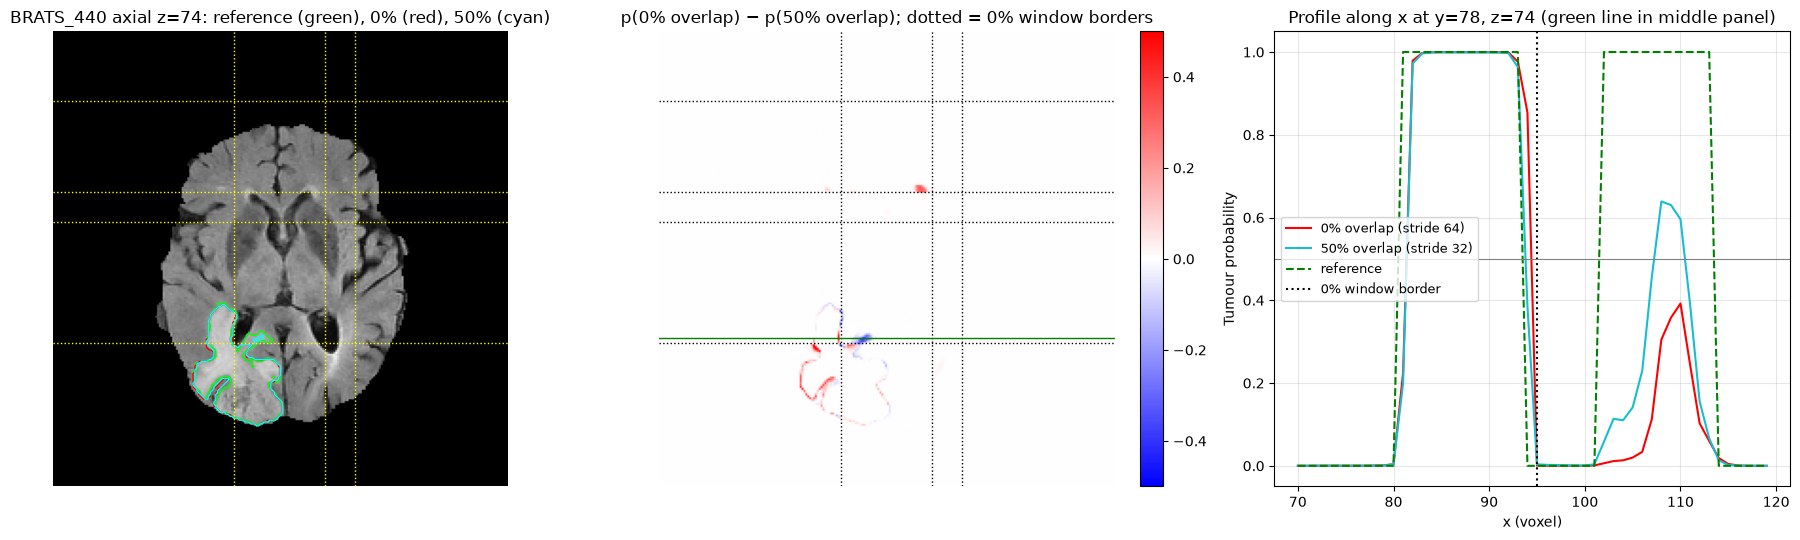

Saved: /home/mohamed.farrag/medass2/figures/bonus_overlap_seams.png


In [86]:
OVERLAPS = [0.0, 0.25, 0.5]
SEAM_CASE = "BRATS_440"

final_model, ep, _ = load_model(RUNS_DIR / FINAL_SAMPLER / "best.pt")
print(f"Frozen model: {FINAL_SAMPLER} best.pt (epoch {ep}) | threshold {THRESHOLD} | no postprocessing")

ov_rows = []
for i, row in test_df.iterrows():
    image, _ = preprocess_case(DATA_ROOT / row["image_relpath"], None, crop_start, crop_size)
    ref = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj) > 0
    for ov in OVERLAPS:
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        prob, info = sliding_window_predict(final_model, image, patch=64, overlap=ov)
        if device.type == "cuda":
            torch.cuda.synchronize()
        ov_rows.append({"case_id": row["case_id"], "overlap": ov, "stride": info["stride"],
                        "n_windows": info["n_windows"], "sec": time.time() - t0,
                        **full_metrics(prob > THRESHOLD, ref)})
    if (i + 1) % 10 == 0:
        print(f"{i + 1}/{len(test_df)} cases done")

ov_df = pd.DataFrame(ov_rows)
ov_df.to_csv(RUNS_DIR / "bonus_overlap_test.csv", index=False)

first_case = ov_df["case_id"].iloc[0]
timing = ov_df[ov_df["case_id"] != first_case]
ov_summary = ov_df.groupby("overlap").agg(
    stride=("stride", "first"), windows=("n_windows", "first"),
    dice_mean=("dice", "mean"), dice_median=("dice", "median"),
    hd95_mean=("hd95_mm", "mean"), hd95_median=("hd95_mm", "median"),
    abs_vol_ml=("abs_vol_err_ml", "mean"), vol_pct=("vol_err_pct", "mean"),
    components=("n_components", "mean"), empty=("empty_pred", "sum"))
ov_summary["sec_per_case"] = timing.groupby("overlap")["sec"].mean()
print("\nOverlap comparison, 73 test cases:")
print(ov_summary.round(4).to_string())

base = ov_df[ov_df["overlap"] == 0.5].set_index("case_id")
for ov in [0.0, 0.25]:
    cur = ov_df[ov_df["overlap"] == ov].set_index("case_id")
    d = cur["dice"] - base["dice"]
    print(f"overlap {ov:.2f} vs 0.50: Dice lower in {int((d < -1e-6).sum())}, higher in {int((d > 1e-6).sum())}, "
          f"mean diff {d.mean():+.4f}, max drop {d.min():+.4f}")


def seam_mask(shape, starts_per_axis, width=2):
    mask = np.zeros(shape, dtype=bool)
    for axis, starts in enumerate(starts_per_axis):
        edges = sorted({s for s in starts if s > 0} | {s + 64 for s in starts if s + 64 < shape[axis]})
        for e in edges:
            sl = [slice(None)] * 3
            sl[axis] = slice(max(e - width, 0), min(e + width, shape[axis]))
            mask[tuple(sl)] = True
    return mask


row = split_df.loc[split_df["case_id"] == SEAM_CASE].iloc[0]
image, _ = preprocess_case(DATA_ROOT / row["image_relpath"], None, crop_start, crop_size)
ref = np.asarray(nib.load(DATA_ROOT / row["label_relpath"]).dataobj) > 0
flair = np.asarray(nib.load(DATA_ROOT / row["image_relpath"]).dataobj)[..., 0]
p0, _ = sliding_window_predict(final_model, image, patch=64, overlap=0.0)
p50, _ = sliding_window_predict(final_model, image, patch=64, overlap=0.5)
diff = p0 - p50

starts0 = [window_starts(s, 64, 64) for s in crop_size]
seams_crop = seam_mask(tuple(crop_size), starts0, width=2)
seams = uncrop(seams_crop.astype(np.uint8), crop_start, original_shape).astype(bool)
brain = flair > 0
near_tumour = ndimage.binary_dilation(ref | (p50 > 0.5), iterations=10) & brain
abs_d = np.abs(diff)
print(f"\nSeam analysis ({SEAM_CASE}), mean |p(0%) − p(50%)| near the tumour:")
print(f"  within 2 voxels of a 0%-overlap window border: {abs_d[near_tumour & seams].mean():.4f}")
print(f"  away from borders:                            {abs_d[near_tumour & ~seams].mean():.4f}")
print(f"  voxels whose 0.5-threshold label flips:        {int(((p0 > 0.5) != (p50 > 0.5)).sum())} "
      f"({((p0 > 0.5) != (p50 > 0.5)).sum() * voxel_ml:.2f} mL)")

z = int(np.argmax(ref.sum(axis=(0, 1))))
x_borders = [e + crop_start[0] for e in sorted({s for s in starts0[0] if s > 0} |
                                               {s + 64 for s in starts0[0] if s + 64 < crop_size[0]})]
y_borders = [e + crop_start[1] for e in sorted({s for s in starts0[1] if s > 0} |
                                               {s + 64 for s in starts0[1] if s + 64 < crop_size[1]})]
tumour_x = np.argwhere(ref[:, :, z])[:, 0]
bx = min(x_borders, key=lambda b: abs(b - np.median(tumour_x)))
band = np.abs(diff[bx - 3:bx + 3, :, z]).max(axis=0)
by = int(np.argmax(band))
xs = np.arange(max(bx - 25, 0), min(bx + 25, original_shape[0]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
axes[0].imshow(flair[:, :, z].T, cmap="gray", origin="lower")
axes[0].contour(ref[:, :, z].T, levels=[0.5], colors="lime", linewidths=1)
axes[0].contour((p0[:, :, z] > 0.5).T, levels=[0.5], colors="red", linewidths=1)
axes[0].contour((p50[:, :, z] > 0.5).T, levels=[0.5], colors="cyan", linewidths=1)
for b in x_borders:
    axes[0].axvline(b, color="yellow", linestyle=":", linewidth=1)
for b in y_borders:
    axes[0].axhline(b, color="yellow", linestyle=":", linewidth=1)
axes[0].set_title(f"{SEAM_CASE} axial z={z}: reference (green), 0% (red), 50% (cyan)")
axes[0].axis("off")

im = axes[1].imshow(diff[:, :, z].T, cmap="bwr", vmin=-0.5, vmax=0.5, origin="lower")
for b in x_borders:
    axes[1].axvline(b, color="black", linestyle=":", linewidth=1)
for b in y_borders:
    axes[1].axhline(b, color="black", linestyle=":", linewidth=1)
axes[1].axhline(by, color="green", linewidth=1)
axes[1].set_title("p(0% overlap) − p(50% overlap); dotted = 0% window borders")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.046)

axes[2].plot(xs, p0[xs, by, z], color="red", label="0% overlap (stride 64)")
axes[2].plot(xs, p50[xs, by, z], color="tab:cyan", label="50% overlap (stride 32)")
axes[2].plot(xs, ref[xs, by, z].astype(float), color="green", linestyle="--", label="reference")
axes[2].axvline(bx, color="black", linestyle=":", label="0% window border")
axes[2].axhline(0.5, color="gray", linewidth=0.8)
axes[2].set_xlabel("x (voxel)")
axes[2].set_ylabel("Tumour probability")
axes[2].set_title(f"Profile along x at y={by}, z={z} (green line in middle panel)")
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "bonus_overlap_seams.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", (FIG_DIR / "bonus_overlap_seams.png").resolve())